# Candidate-Region Review


- What measured-genotype evidence surrounds the breed-specific candidate markers?
- Regional plots, linkage disequilibrium, carrier summaries, and sensitivity comparisons examine LR and GSP candidates from the primary GWAS.
- These methods describe neighboring association evidence, observed genotypes, relatedness, and sensitivity to control definitions or individual cases.
- They do not identify causal variants, independent loci, or fine-mapping credible sets.

### (Initialization) Import Directory-Free Helpers


### (Region Selection) Select Display Regions
- Candidates receive ±500 kb windows; overlapping windows within a breed merge for display.
- The smallest-Wald candidate anchors each plot without being assumed causal.
- *review_gwas_candidates.py*

In [1]:
# Load the candidate-region review and verify its settings, reporting policy and source preservation.
# Display the candidate and region counts to make the scope of follow-up explicit.

from pathlib import Path
import importlib
import sys
study_root = next(p for p in [Path.cwd(), *Path.cwd().parents]
                  if (p / "scripts/notebook_support.py").exists())
sys.path.insert(0, str(study_root / "scripts"))
read_json = importlib.import_module("notebook_support").read_json
file_digest = importlib.import_module("notebook_support").file_digest
require_saved = importlib.import_module("notebook_review").require_saved
run_script = importlib.import_module("notebook_support").run_script
review_folder = study_root / "results/private/version2/09_candidate_review"
# run_script(study_root, "review_gwas_candidates.py", "--results-dir", review_folder)
review = read_json(review_folder / "summary.private.json")
assert review["status"] == "candidate_regions_reviewed"
assert review["original_sources_unchanged"]
assert review["review_config_sha256"] == file_digest(study_root / "config/candidate_review.json")
assert review["reporting_policy_sha256"] == file_digest(study_root / "config/gwas_reporting.json")
from IPython.display import Markdown, Image, display
lines = ["| Breed | Selected Candidate Markers | Display Regions | Cases |",
         "| :---: | :---: | :---: | :---: |"]
for row in review["flow"]:
    lines.append(f"| {row['breed']} | {row['selected_markers']} | {row['display_regions']} | {row['cases']} |")
display(Markdown("\n".join(lines)))

| Breed | Selected Candidate Markers | Display Regions | Cases |
| :---: | :---: | :---: | :---: |
| LR | 3 | 3 | 7 |
| GSP | 21 | 16 | 9 |

### (Linkage Disequilibrium) Neighboring Marker Support
- Markers are colored by measured r² with the anchor, omitting missing calls pairwise.
- Correlated neighbors are not independent replications.
- Isolated signals can reflect sparse coverage, narrow effects or unstable tests.

In [2]:
# Define measured-marker squared correlation using dogs observed at both markers, then show saved neighborhood counts.
# This separates correlated regional support from independent association evidence.

import numpy as np

def measured_r_squared(anchor, neighbor):
    """Compare two measured markers using only dogs observed at both."""
    observed = np.isfinite(anchor) & np.isfinite(neighbor)
    if observed.sum() < 3 or np.std(anchor[observed]) == 0 or np.std(neighbor[observed]) == 0:
        return None
    return float(np.corrcoef(anchor[observed], neighbor[observed])[0, 1] ** 2)

lines = ['| Region | Display Anchor | Candidate Markers | Measured Neighbors | Other Neighbors With r² ≥ 0.8 |',
         "| :---: | :---: | :---: | :---: | :---: |"]
for region in review["regions"]:
    lines.append(f"| {region['region']} | chr{region['chromosome']}:{region['anchor_position']} | {len(region['selected_markers'])} | "
                 f"{region['measured_neighbors']} | {region['nonanchor_neighbors_r2_ge_08']} |")
display(Markdown("\n".join(lines)))

| Region | Display Anchor | Candidate Markers | Measured Neighbors | Other Neighbors With r² ≥ 0.8 |
| :---: | :---: | :---: | :---: | :---: |
| LR_01_chr5 | chr5:5769564 | 1 | 77 | 0 |
| LR_02_chr7 | chr7:11092834 | 1 | 92 | 1 |
| LR_03_chr8 | chr8:18070392 | 1 | 64 | 1 |
| GSP_01_chr1 | chr1:46541651 | 1 | 55 | 1 |
| GSP_02_chr2 | chr2:76618161 | 1 | 77 | 1 |
| GSP_03_chr6 | chr6:62697032 | 1 | 57 | 0 |
| GSP_04_chr8 | chr8:32430162 | 1 | 69 | 1 |
| GSP_05_chr10 | chr10:26712899 | 1 | 116 | 0 |
| GSP_06_chr17 | chr17:59758927 | 1 | 78 | 0 |
| GSP_07_chr17 | chr17:62379190 | 1 | 65 | 1 |
| GSP_08_chr19 | chr19:29781532 | 2 | 91 | 0 |
| GSP_09_chr21 | chr21:22578309 | 1 | 74 | 0 |
| GSP_10_chr27 | chr27:38155972 | 3 | 89 | 2 |
| GSP_11_chr30 | chr30:17529608 | 1 | 78 | 0 |
| GSP_12_chr32 | chr32:4262864 | 1 | 67 | 0 |
| GSP_13_chr32 | chr32:30780290 | 1 | 91 | 0 |
| GSP_14_chr34 | chr34:9792065 | 2 | 79 | 1 |
| GSP_15_chr37 | chr37:28424522 | 2 | 99 | 1 |
| GSP_16_chr38 | chr38:21334868 | 1 | 91 | 0 |

### (Summary) Genotypes and Carriers
- Plots use observed proportions.
- Carriers have a copy of the less frequent Scheme A anchor allele, not automatically a risk allele.
- Summaries split carriers by outcome and recorded sex.
- Pairwise similarity is descriptive; shared dogs make pairs dependent.

In [3]:
# Summarize observed anchor-allele carriers by outcome and recorded sex.
# These aggregate counts help identify sparse or sex-concentrated genotype patterns.

import csv
with (review_folder / "anchor_genotypes.private.tsv").open(encoding="utf-8", newline="") as handle:
    counts = list(csv.DictReader(handle, delimiter="\t"))
lines = ["| Region | Carrier Allele | Case Carriers (M/F) | Control Carriers (M/F) |",
         "| :---: | :---: | :---: | :---: |"]
for region in review["regions"]:
    rows = [r for r in counts if r["region"] == region["region"]]
    def carrier_count(group, sex):
        return next(r["minor_allele_carriers"] for r in rows if r["group"] == group and r["sex"] == sex)
    lines.append(f"| {region['region']} | {region['carrier_allele']} | "
                 f"{carrier_count('case', 'male')} / {carrier_count('case', 'female')} | "
                 f"{carrier_count('control', 'male')} / {carrier_count('control', 'female')} |")
display(Markdown("\n".join(lines)))

| Region | Carrier Allele | Case Carriers (M/F) | Control Carriers (M/F) |
| :---: | :---: | :---: | :---: |
| LR_01_chr5 | T | 2 / 3 | 1 / 0 |
| LR_02_chr7 | C | 3 / 2 | 2 / 0 |
| LR_03_chr8 | T | 3 / 4 | 4 / 1 |
| GSP_01_chr1 | T | 2 / 1 | 0 / 1 |
| GSP_02_chr2 | T | 3 / 3 | 6 / 3 |
| GSP_03_chr6 | T | 2 / 2 | 1 / 2 |
| GSP_04_chr8 | A | 2 / 2 | 4 / 1 |
| GSP_05_chr10 | G | 2 / 3 | 3 / 4 |
| GSP_06_chr17 | T | 3 / 3 | 4 / 2 |
| GSP_07_chr17 | T | 3 / 3 | 5 / 6 |
| GSP_08_chr19 | T | 2 / 4 | 4 / 3 |
| GSP_09_chr21 | C | 2 / 1 | 3 / 0 |
| GSP_10_chr27 | C | 1 / 3 | 2 / 0 |
| GSP_11_chr30 | T | 2 / 1 | 1 / 0 |
| GSP_12_chr32 | A | 2 / 2 | 3 / 3 |
| GSP_13_chr32 | C | 2 / 1 | 0 / 1 |
| GSP_14_chr34 | T | 2 / 1 | 0 / 2 |
| GSP_15_chr37 | C | 3 / 2 | 1 / 3 |
| GSP_16_chr38 | C | 2 / 2 | 2 / 0 |

### (Visualization) Candidate-Region Charts


## LR: candidate-region figures

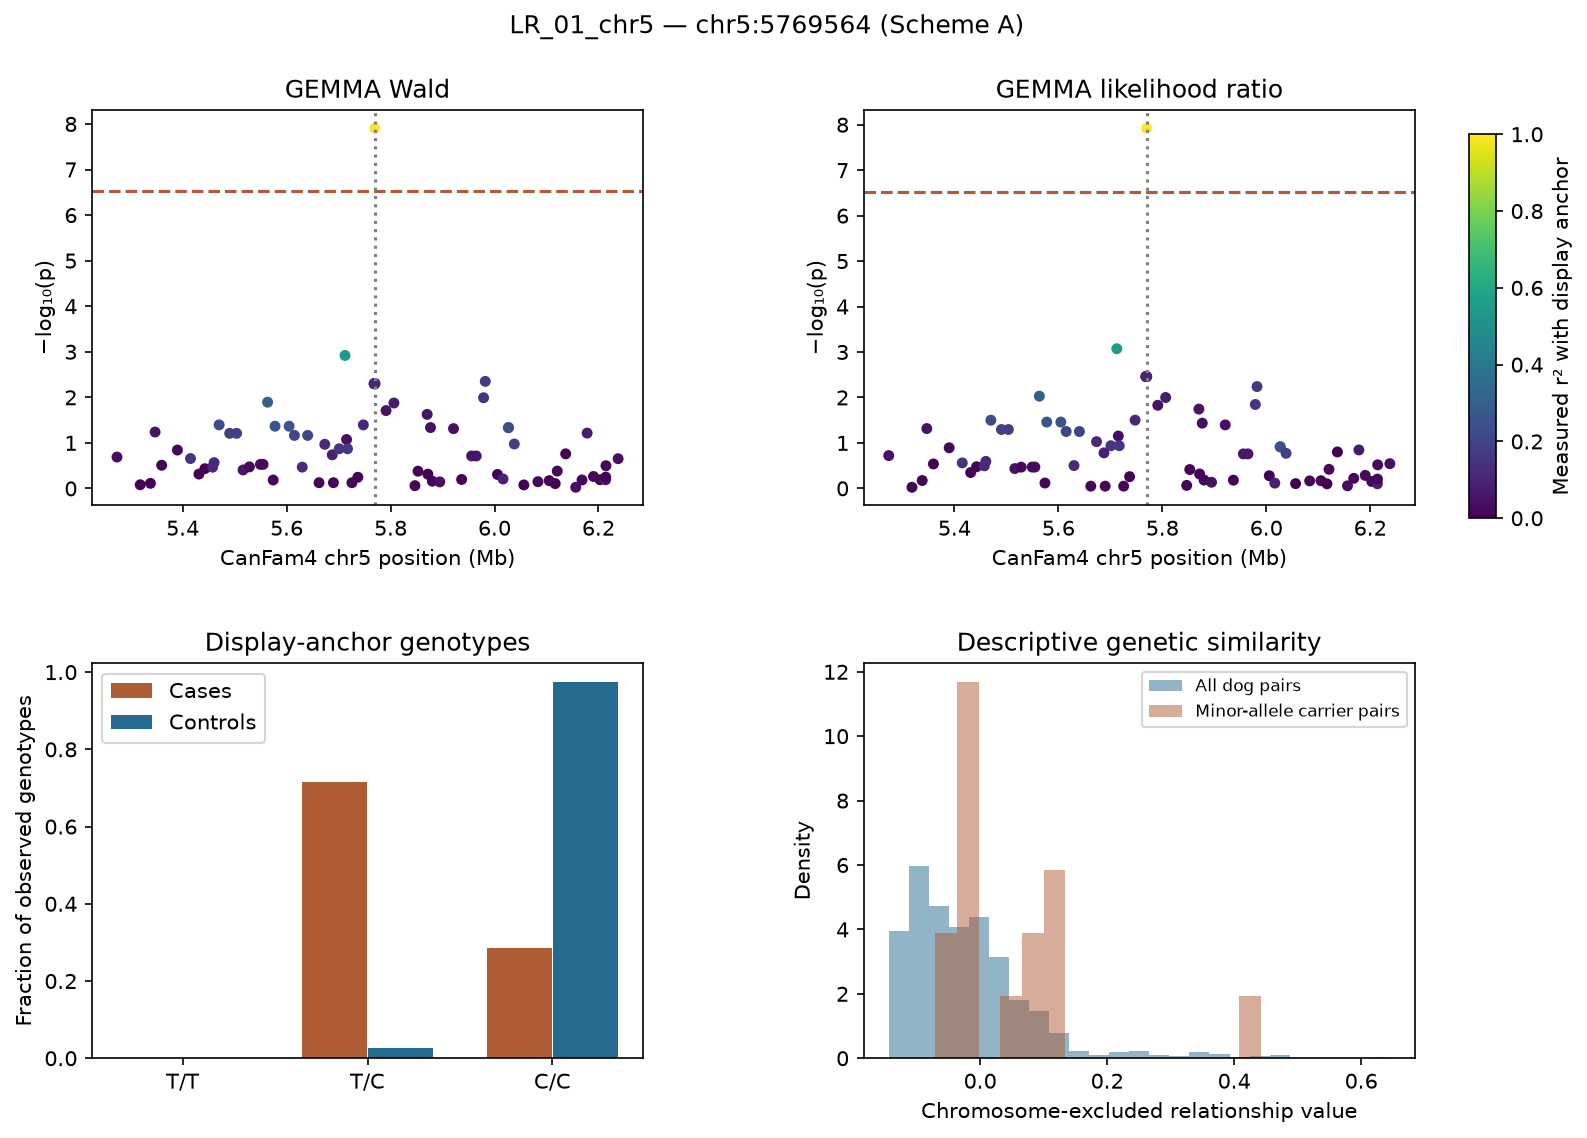

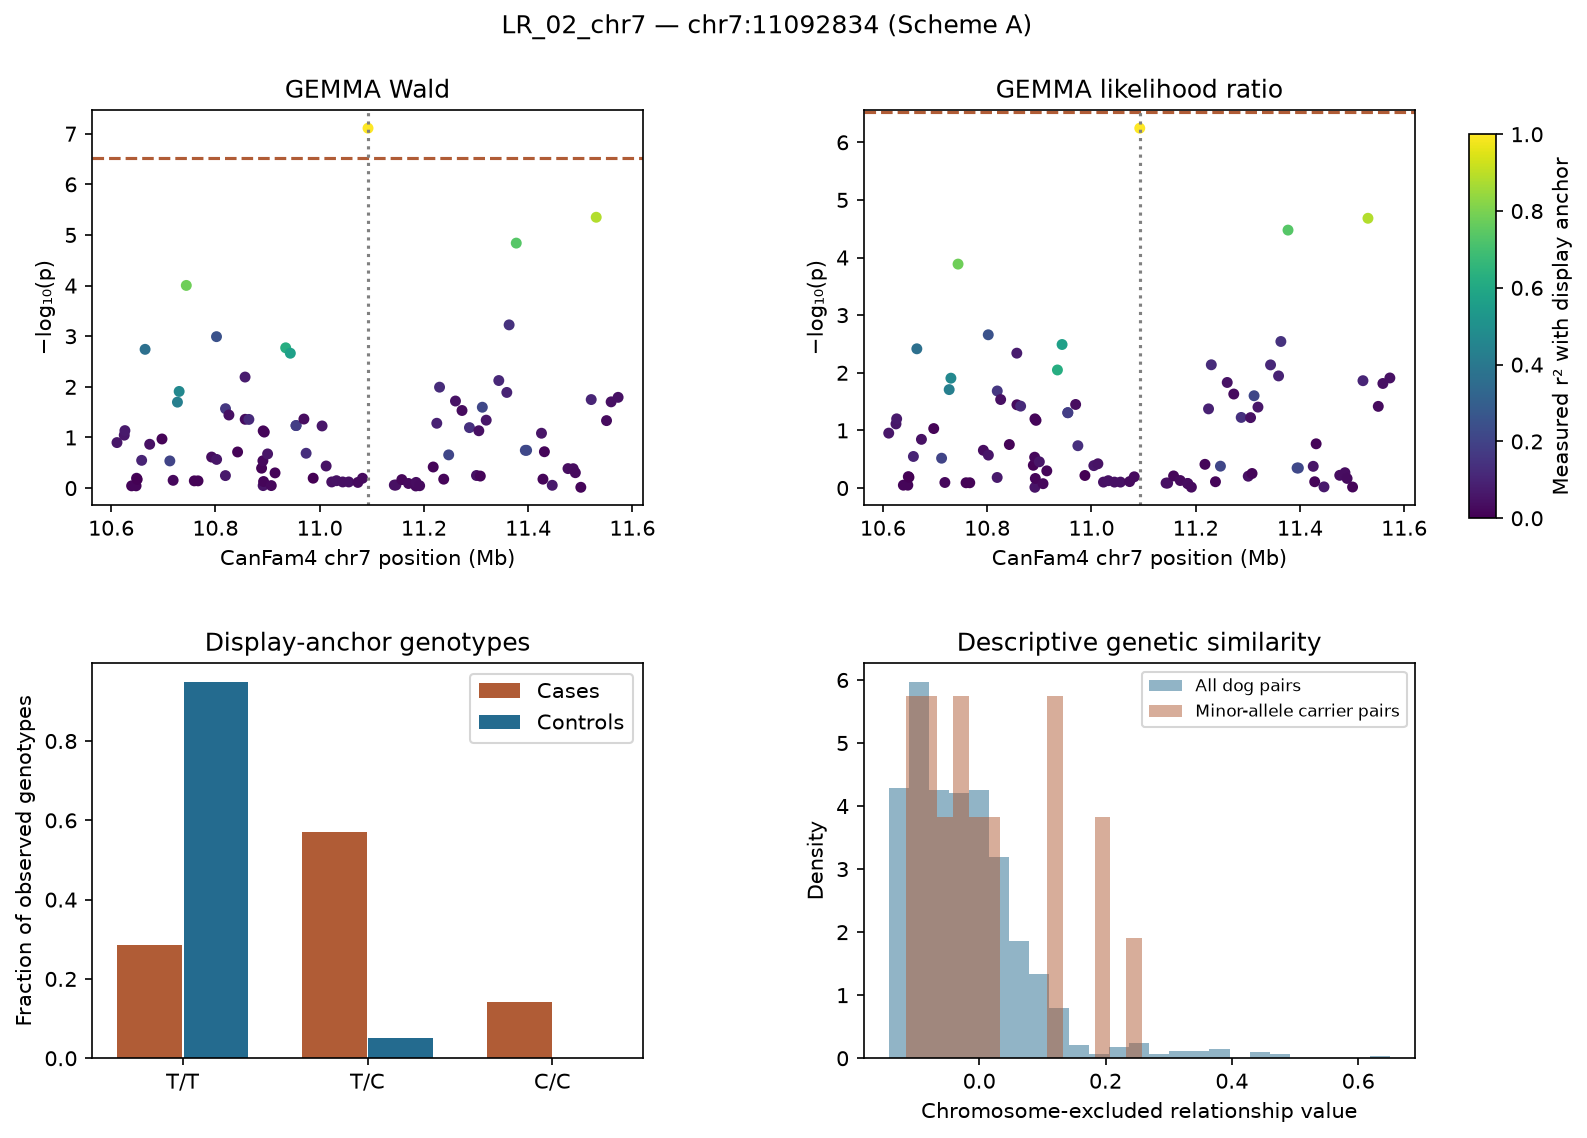

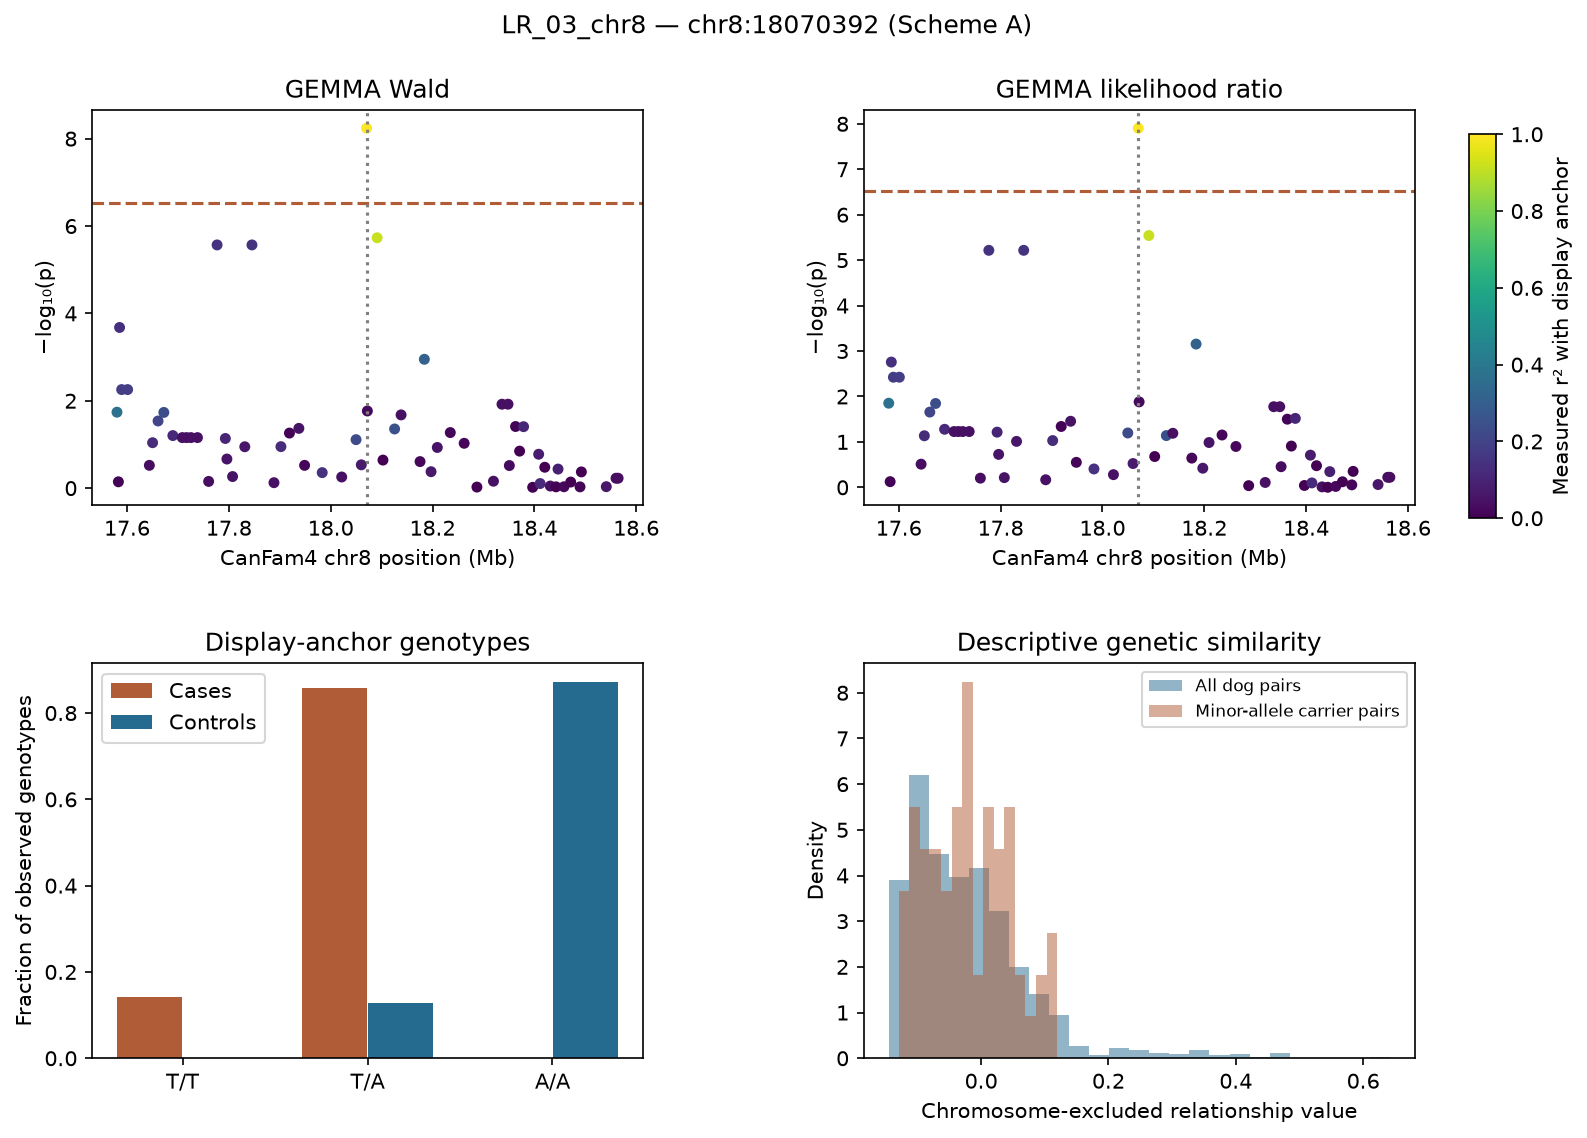

## GSP: candidate-region figures

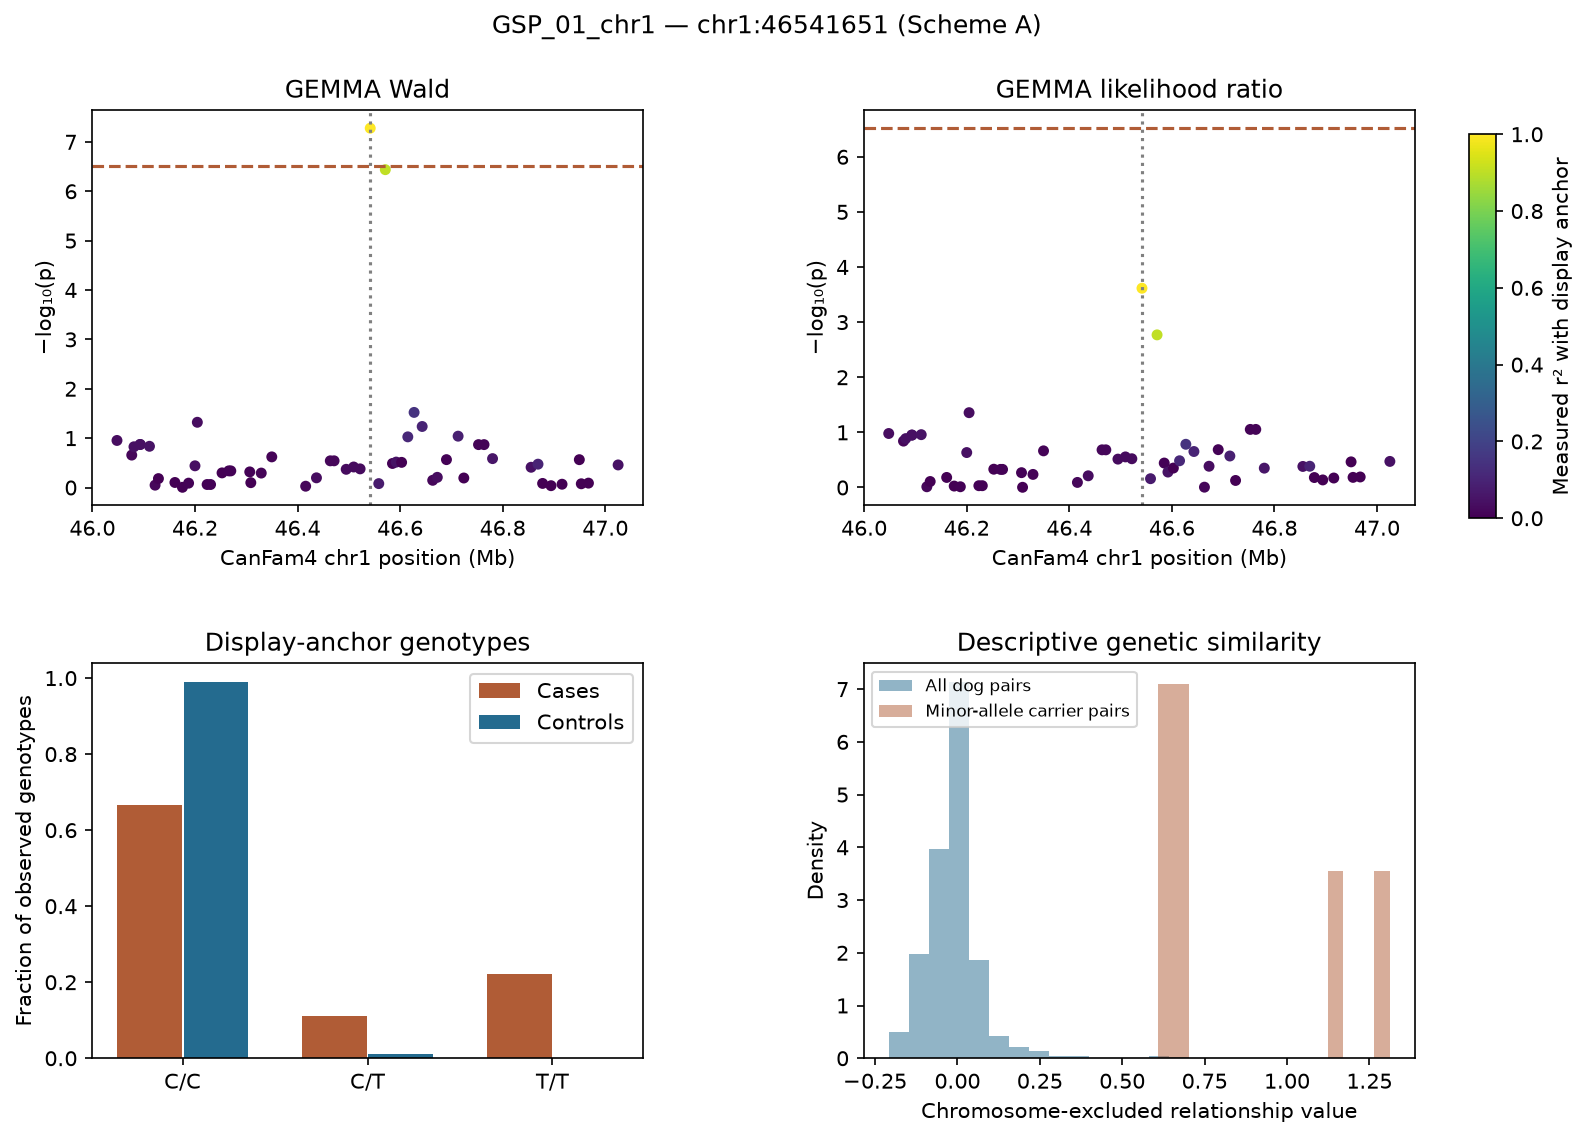

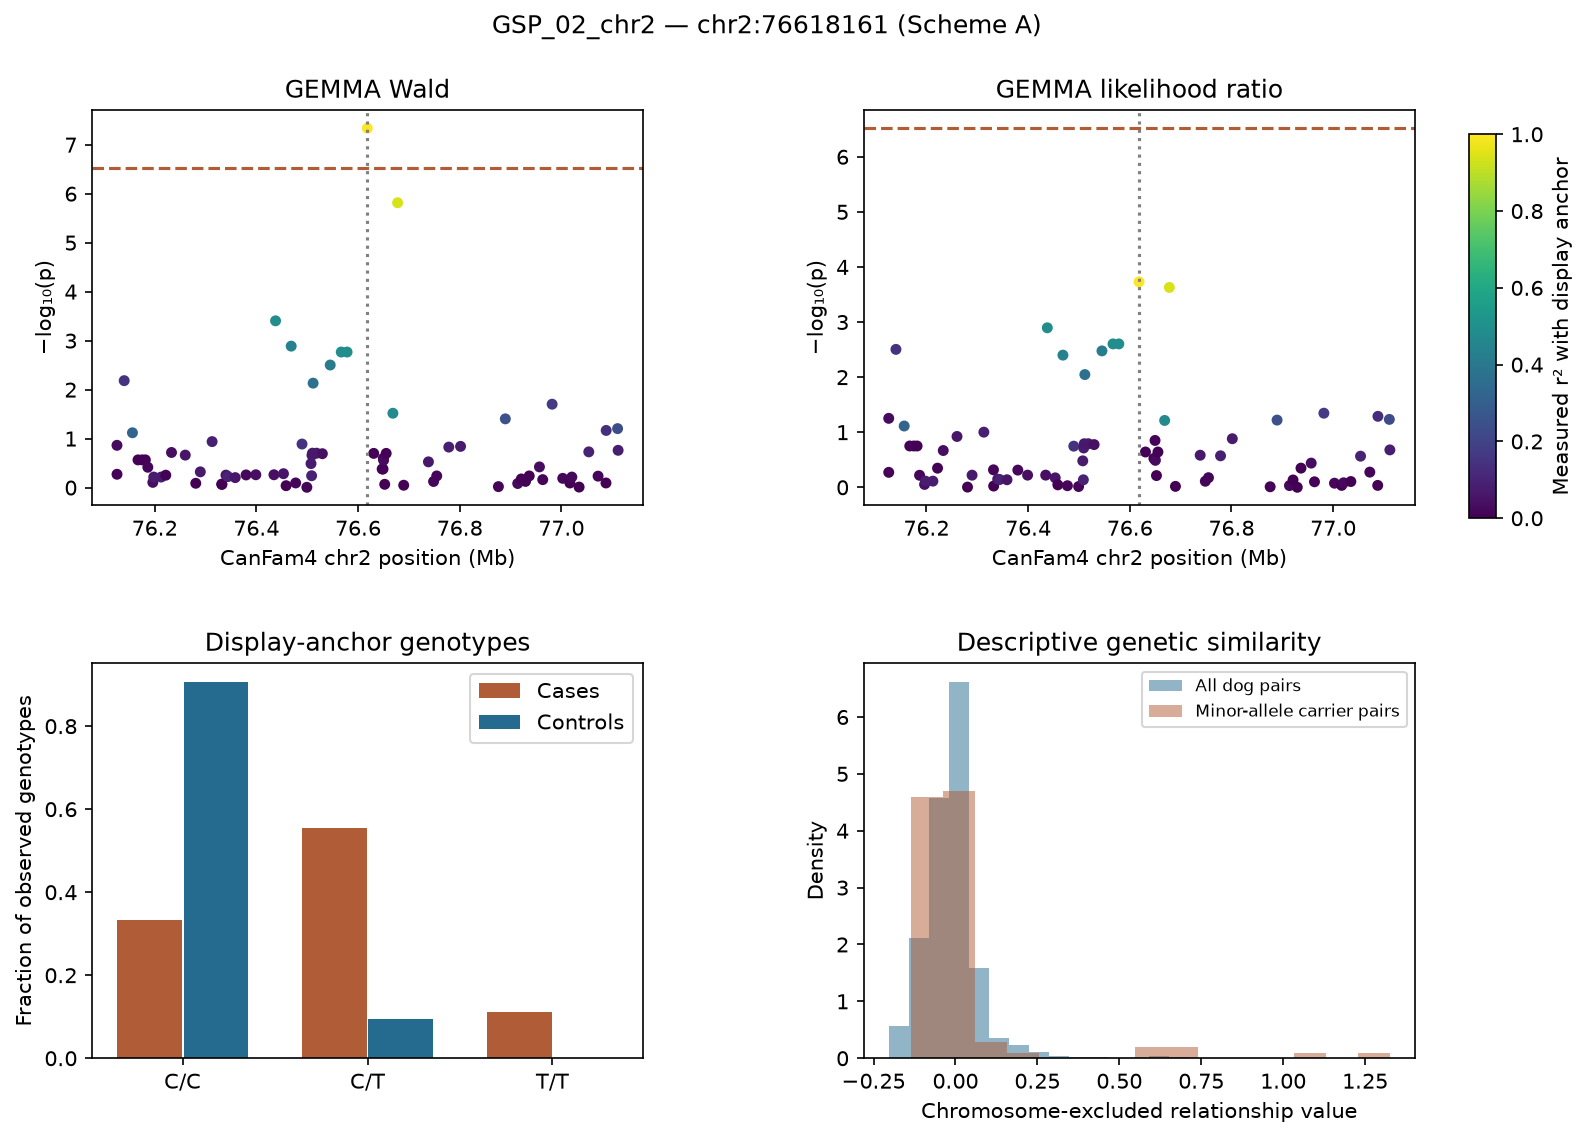

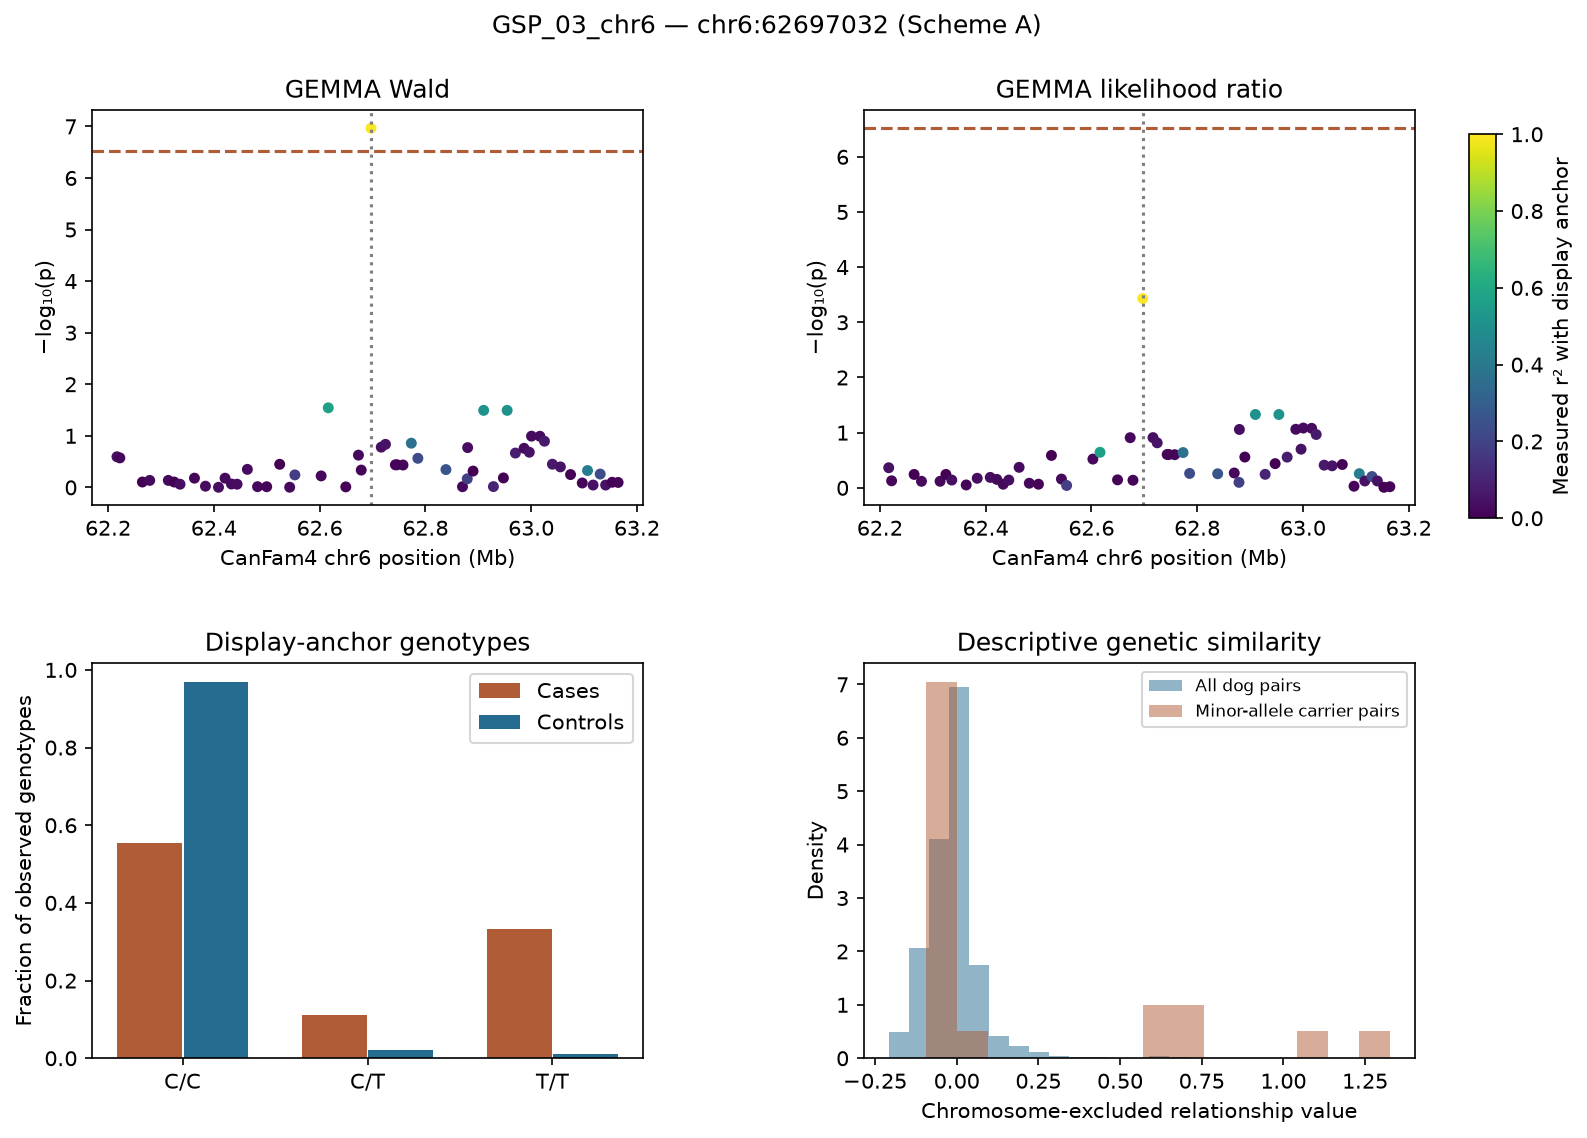

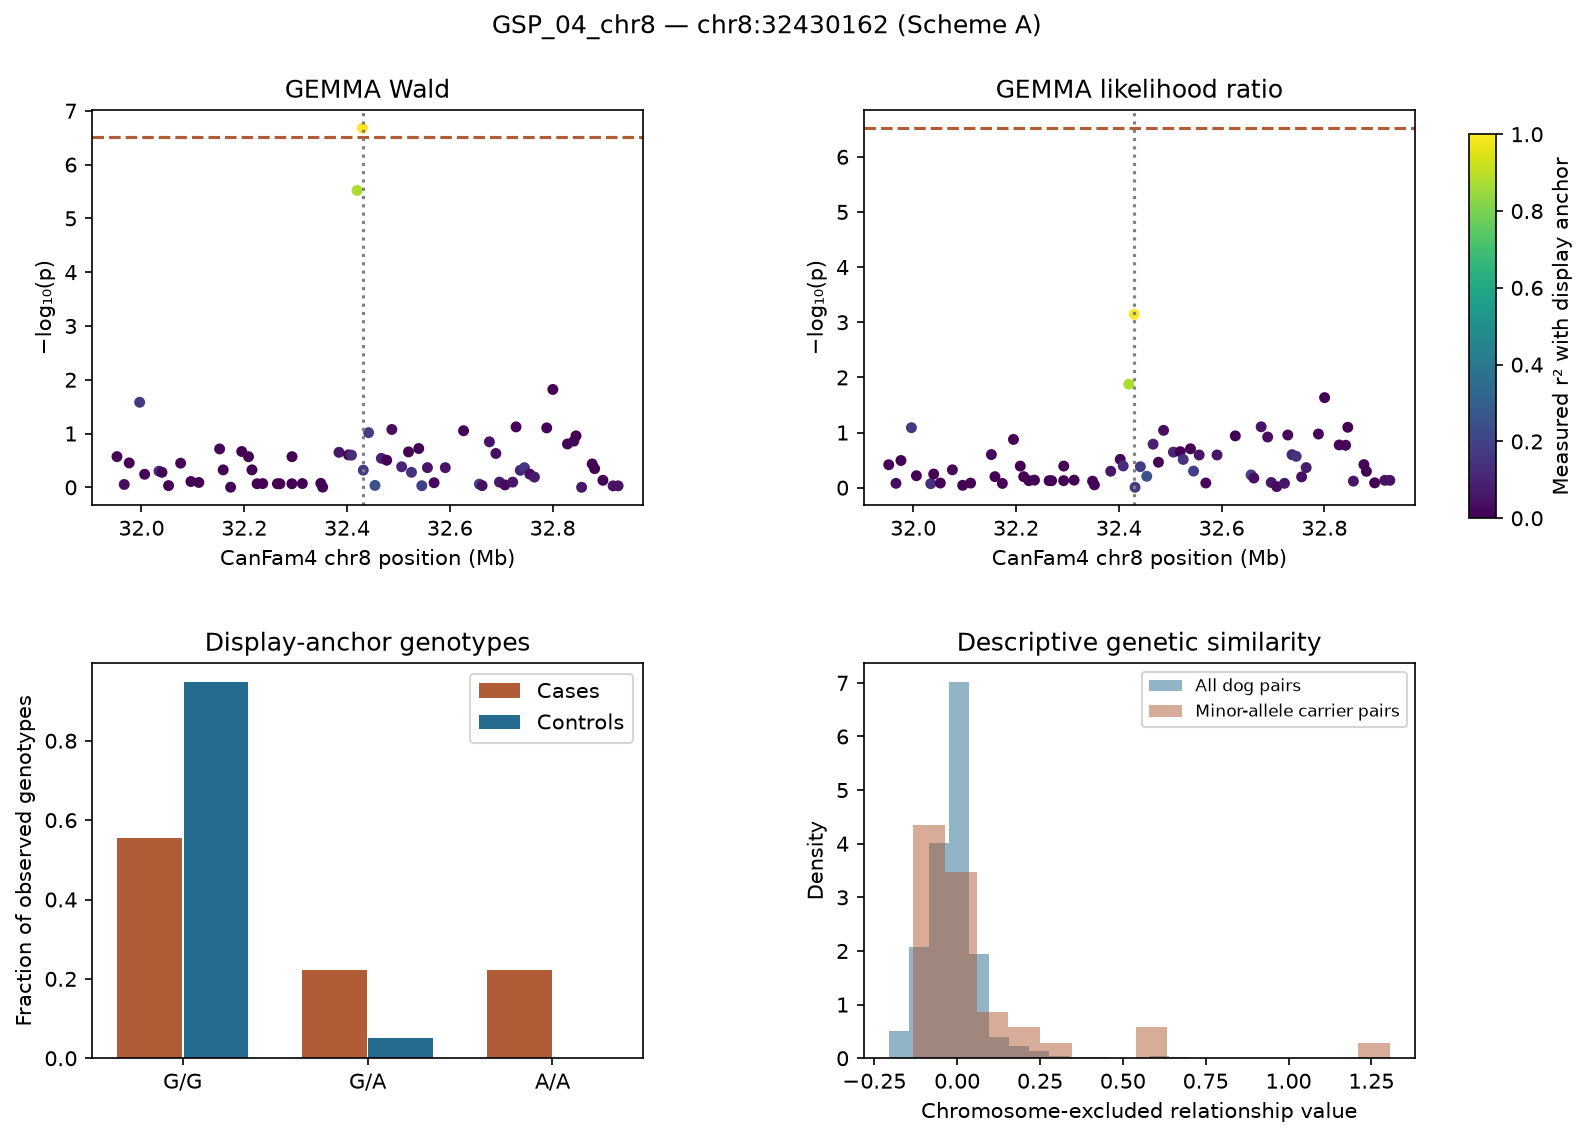

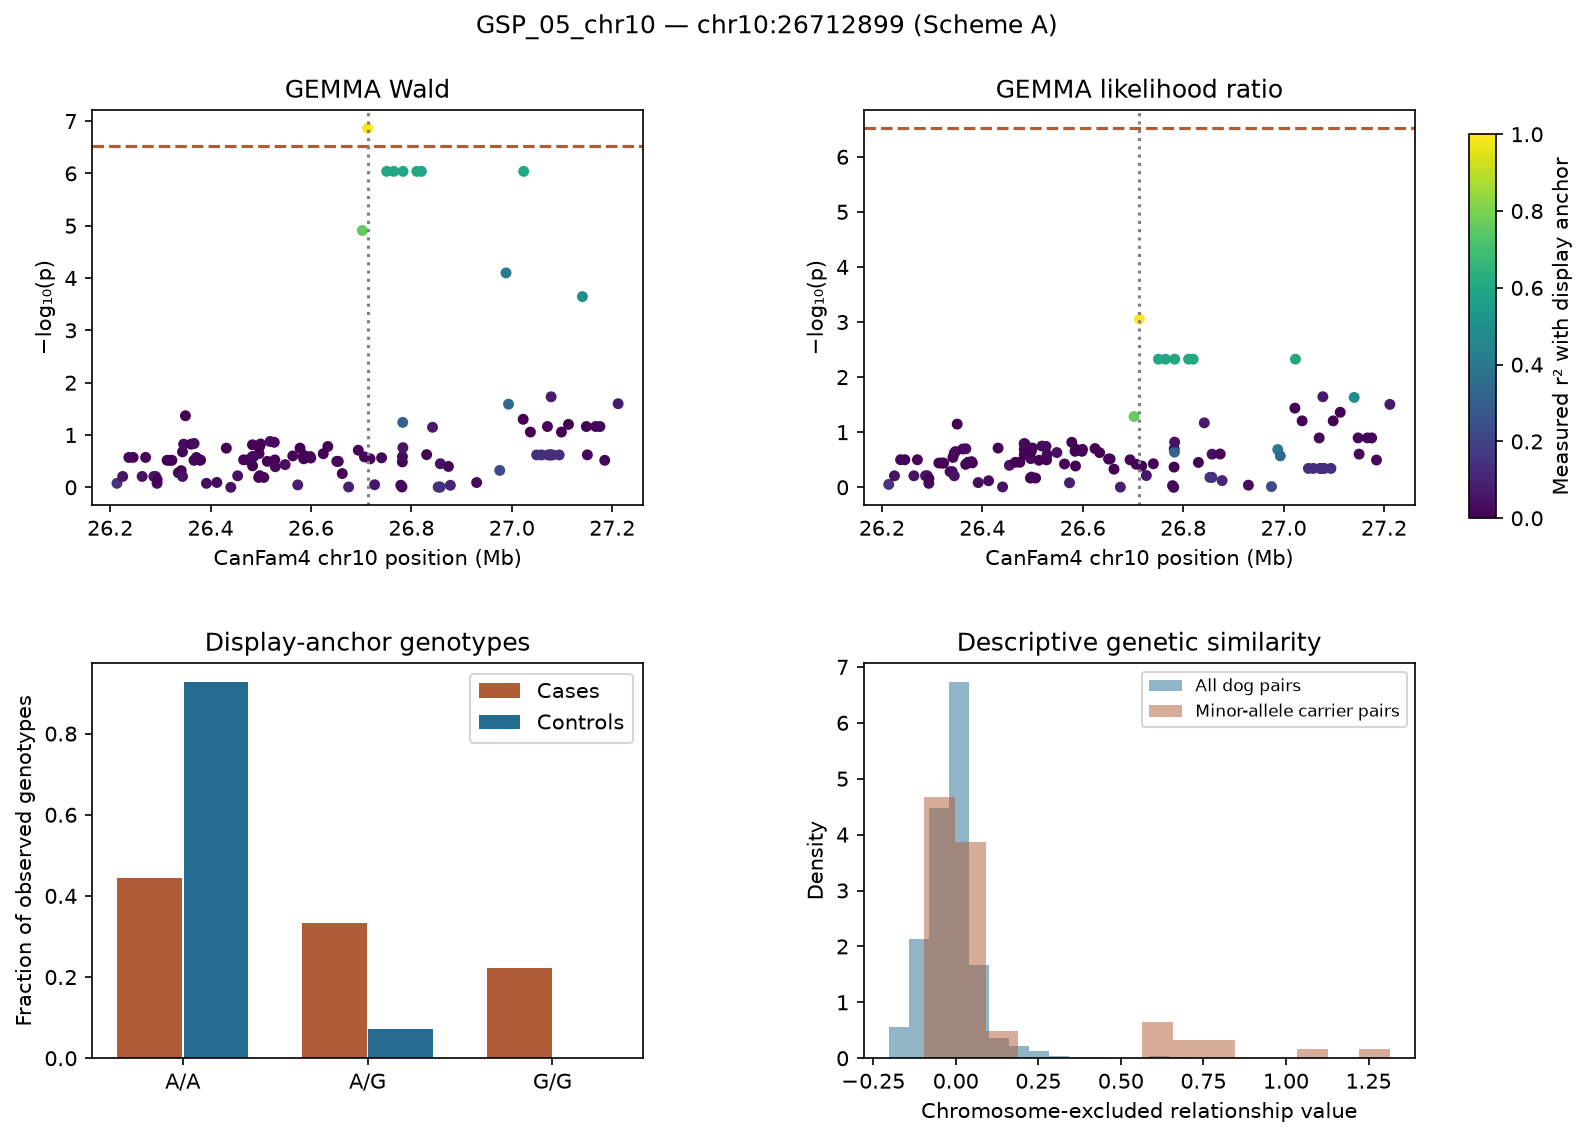

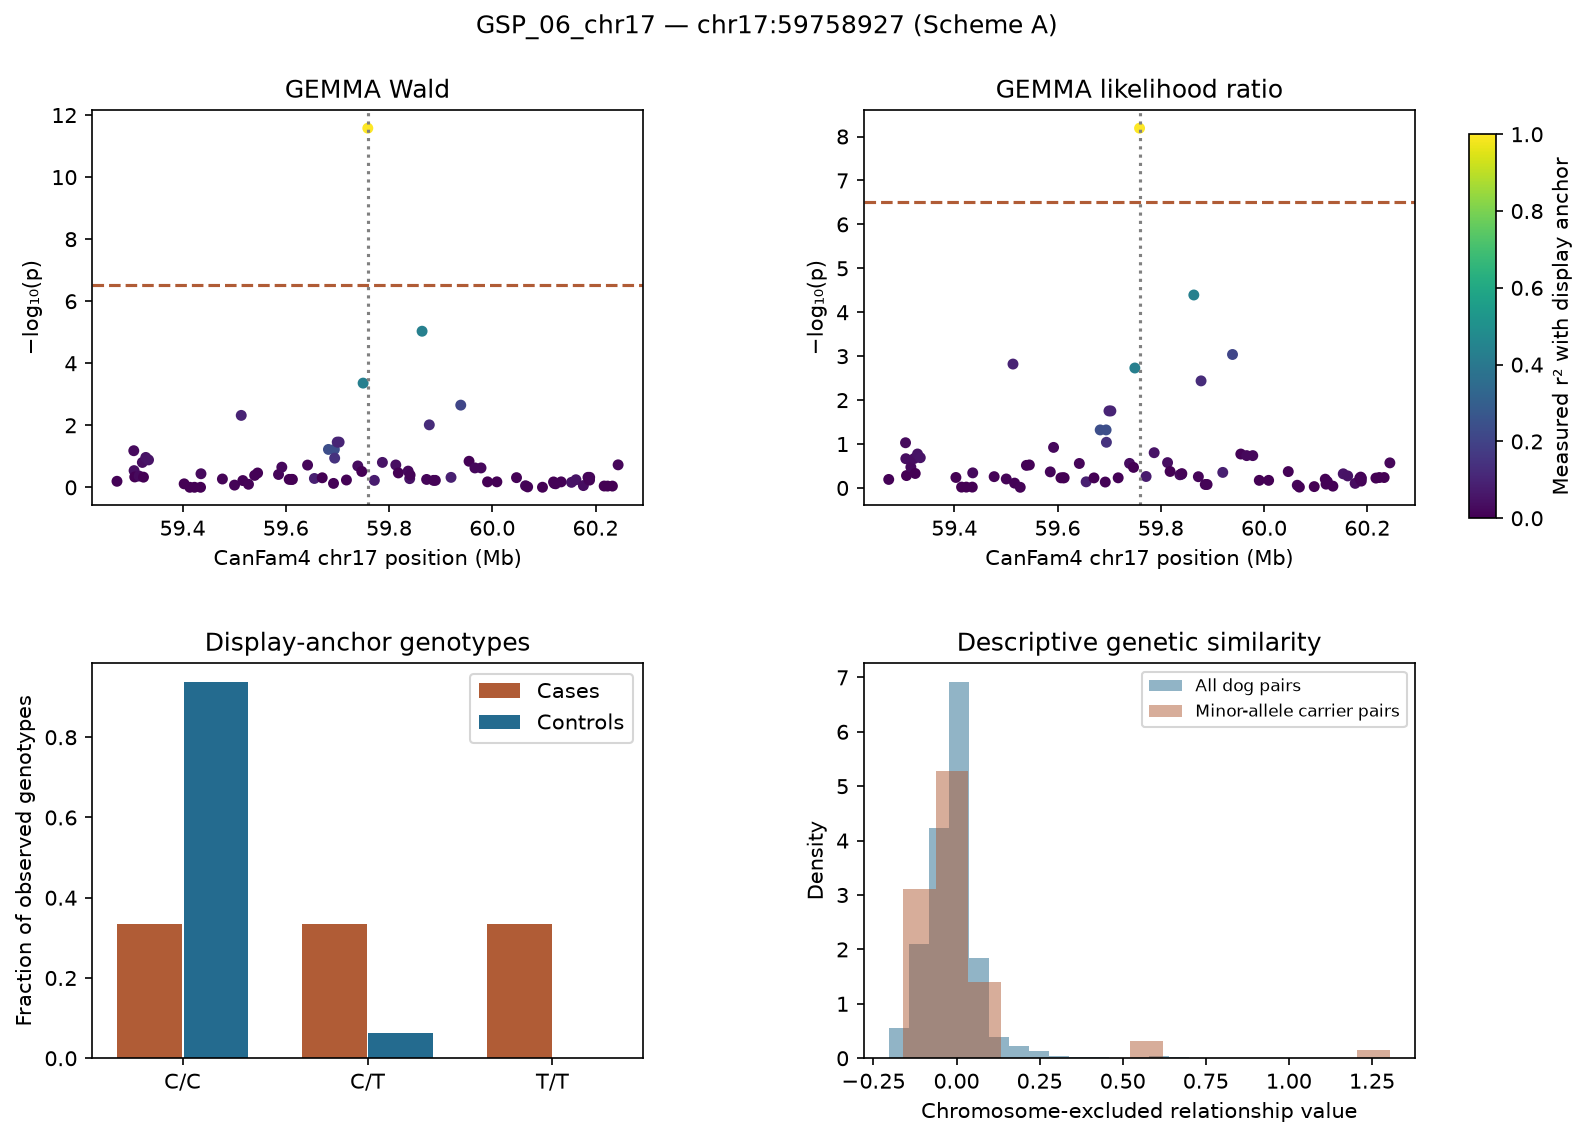

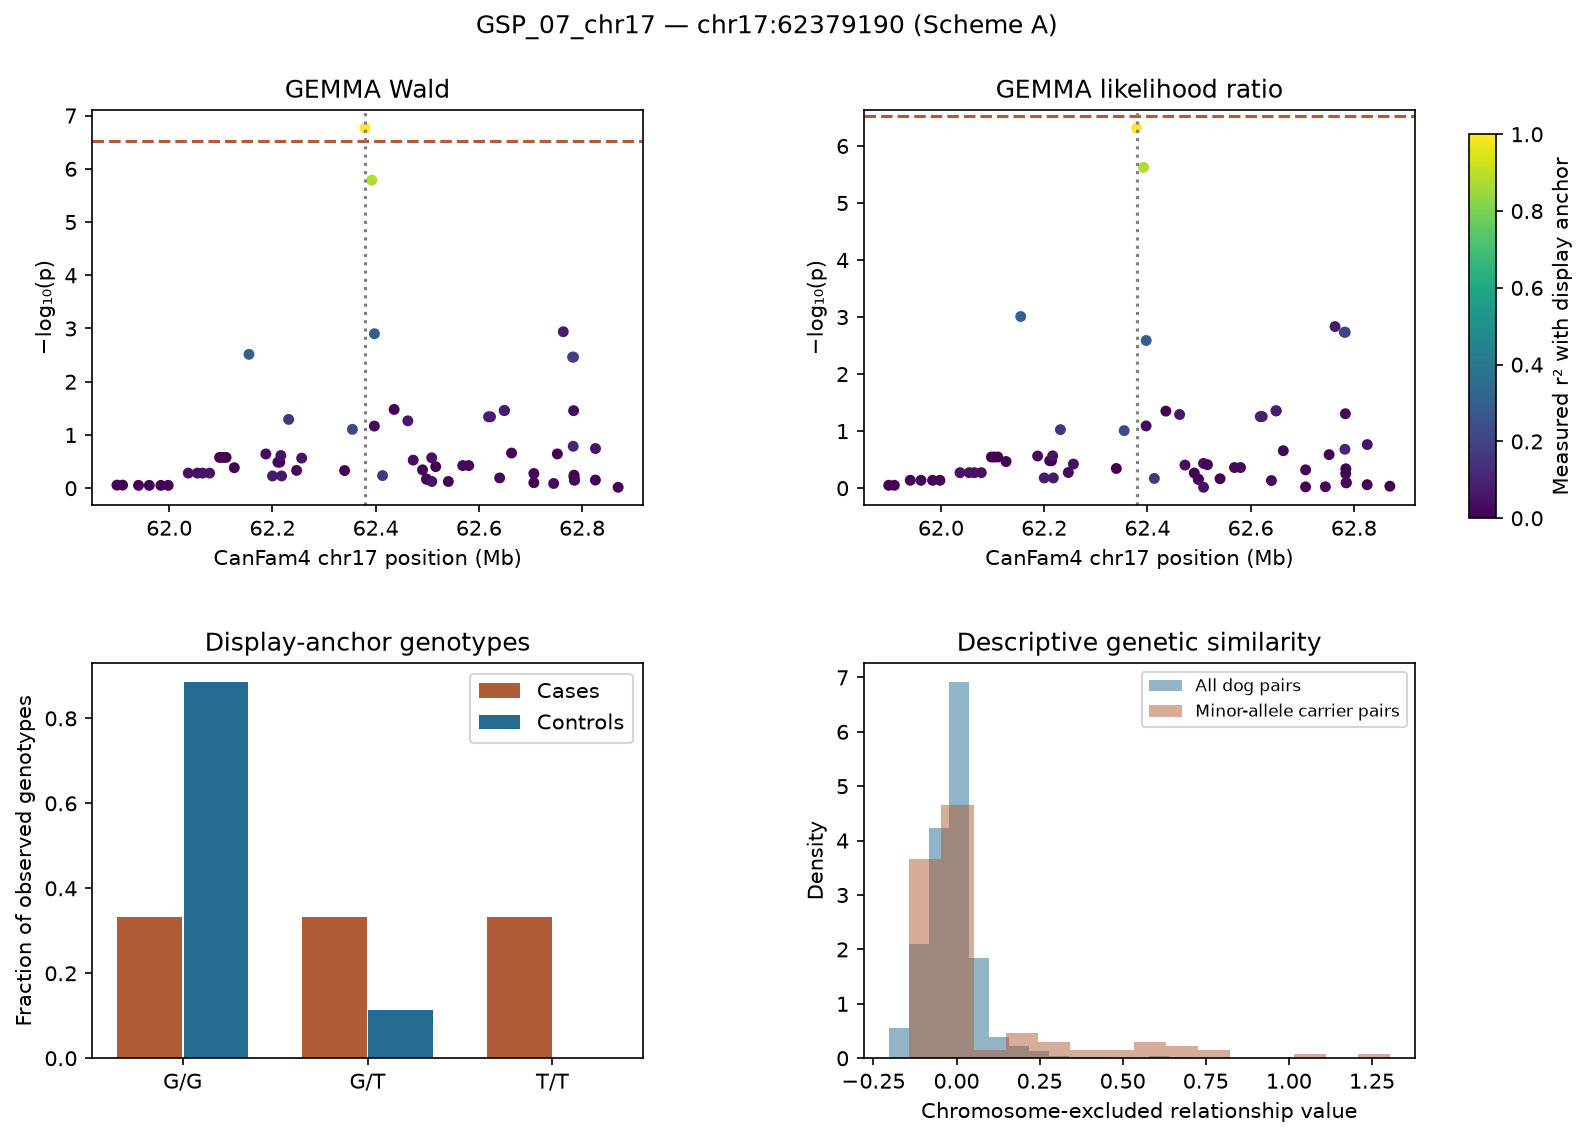

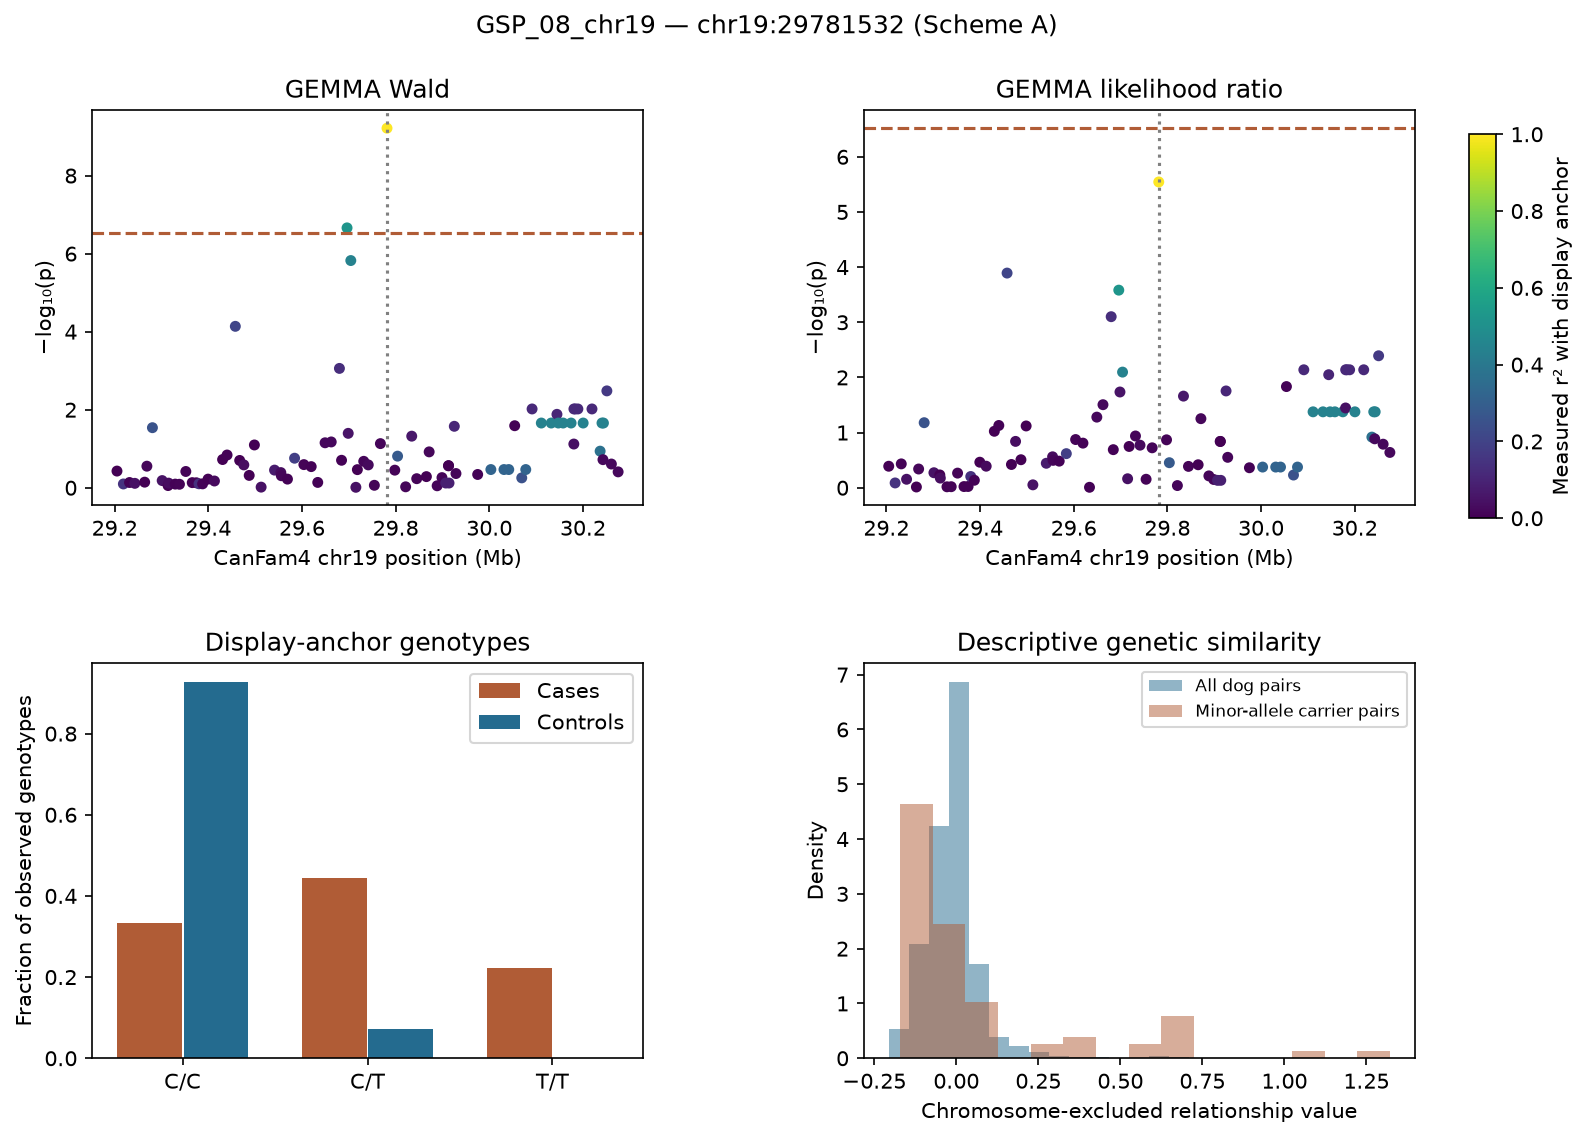

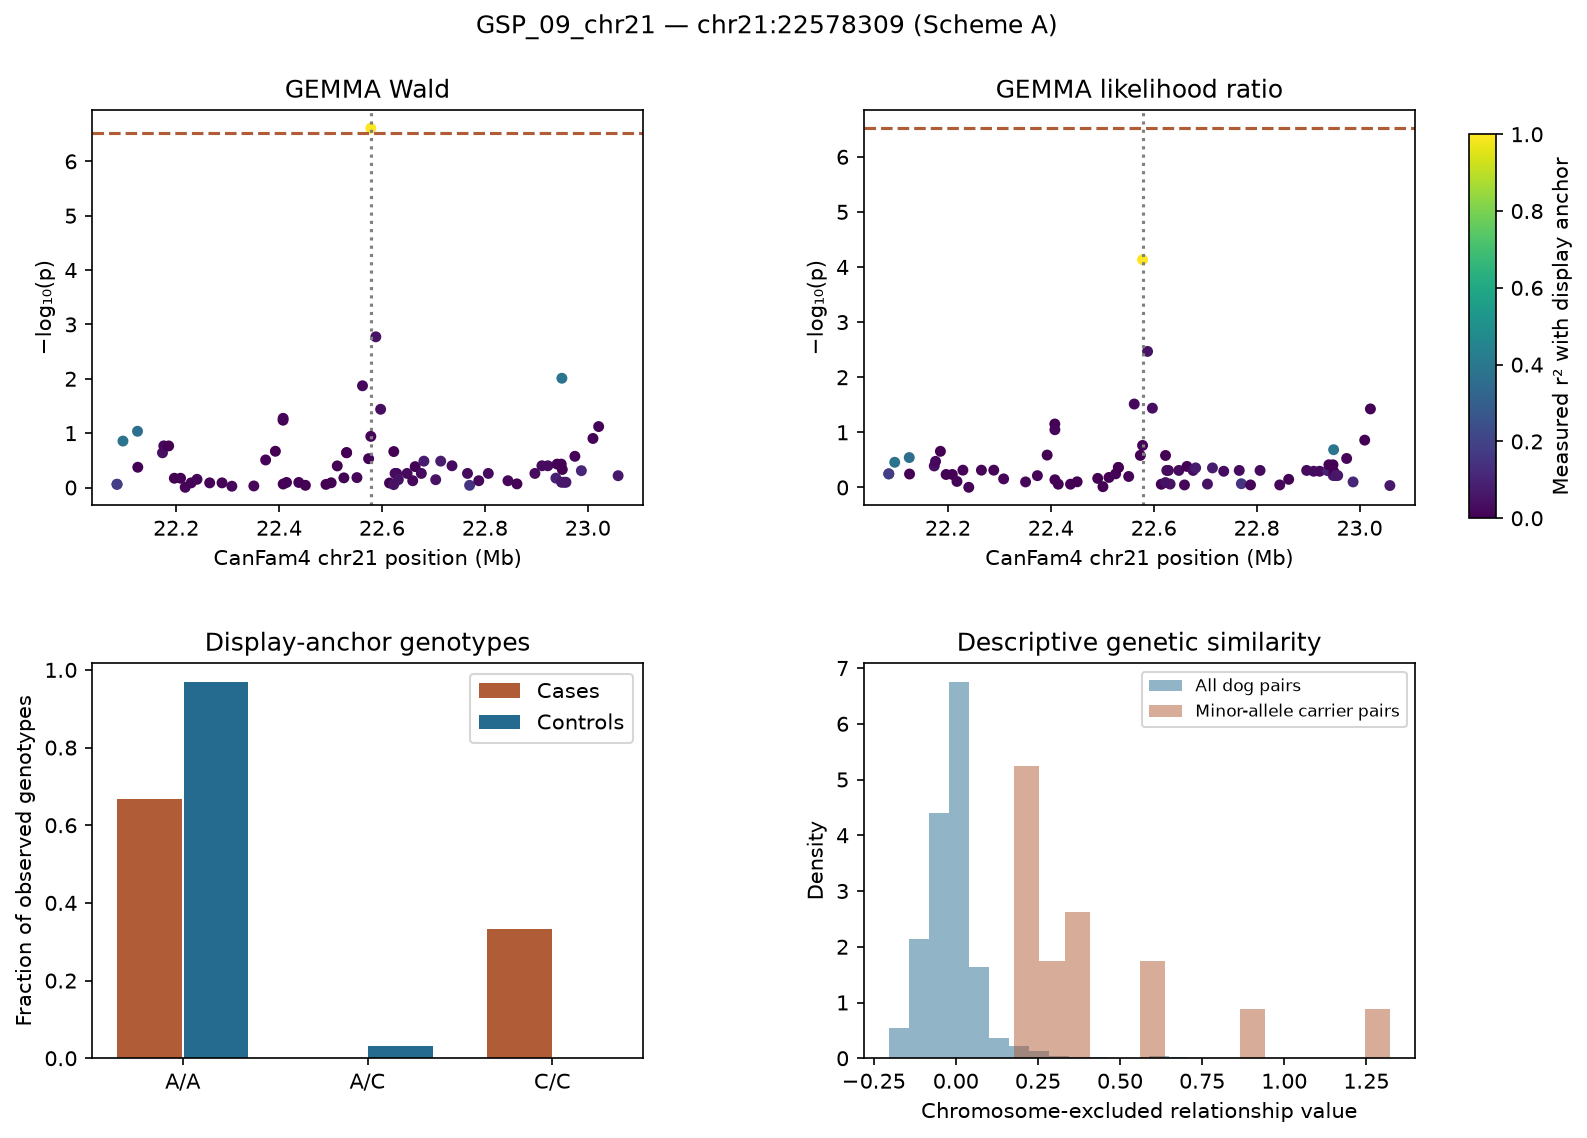

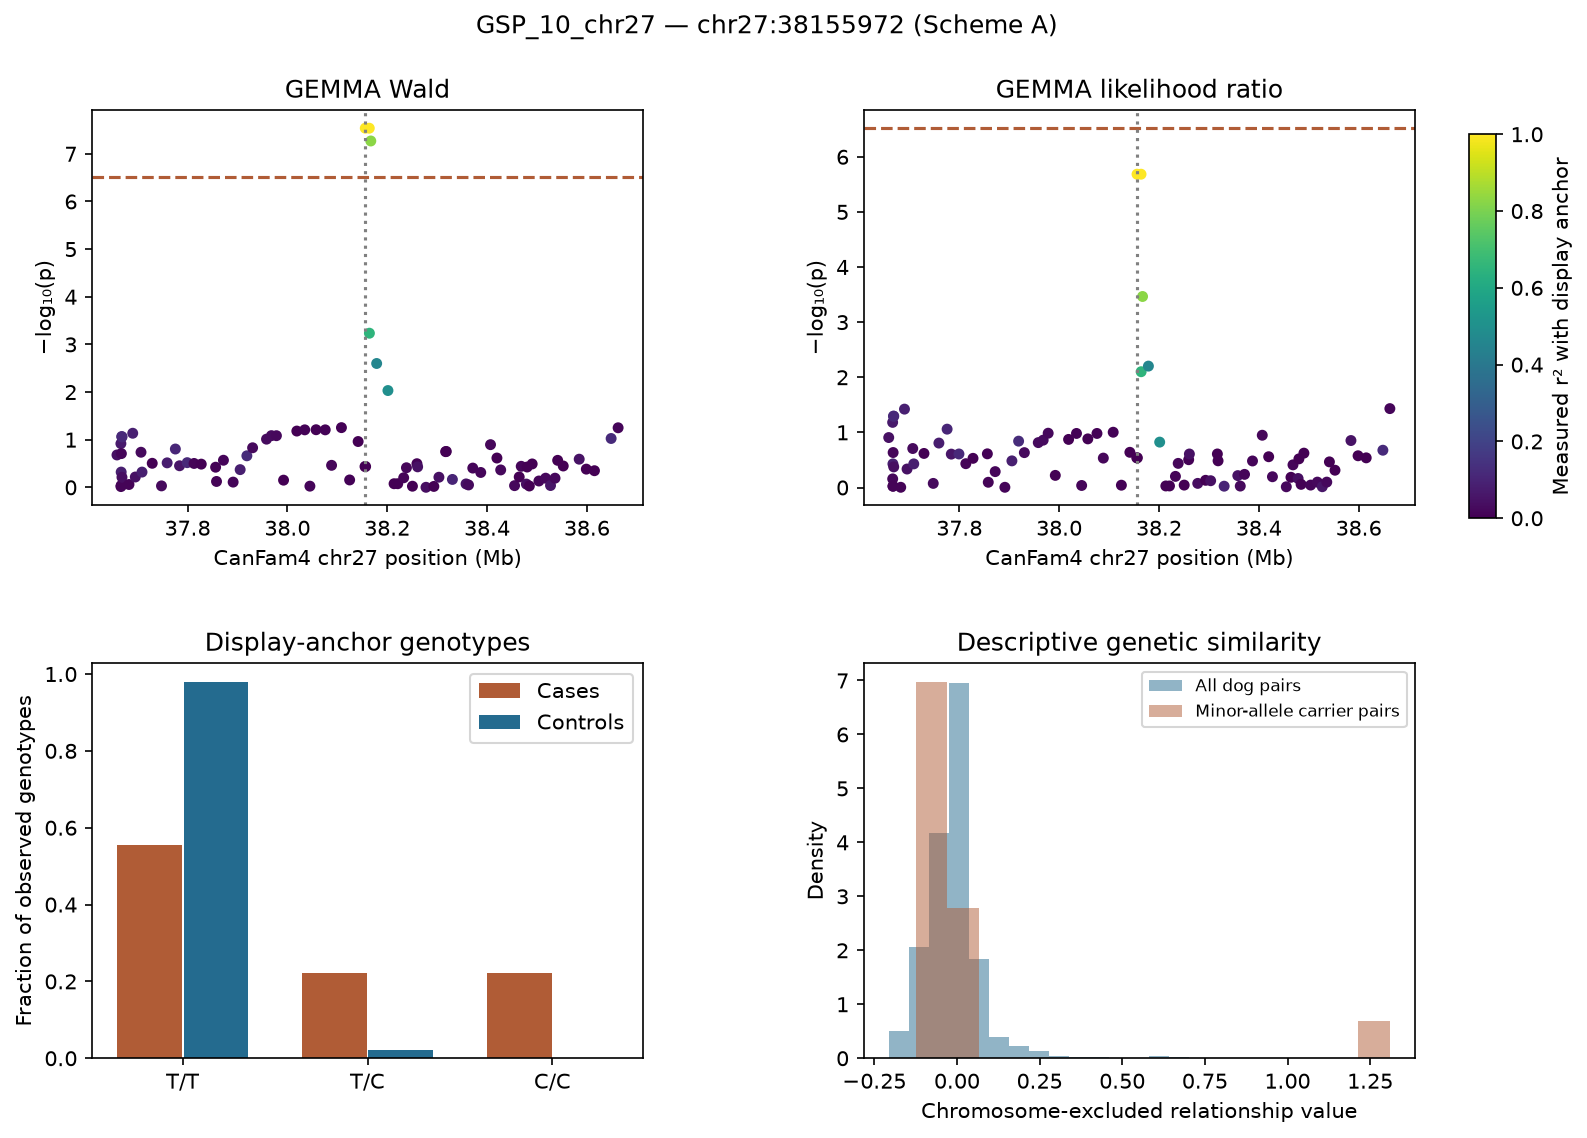

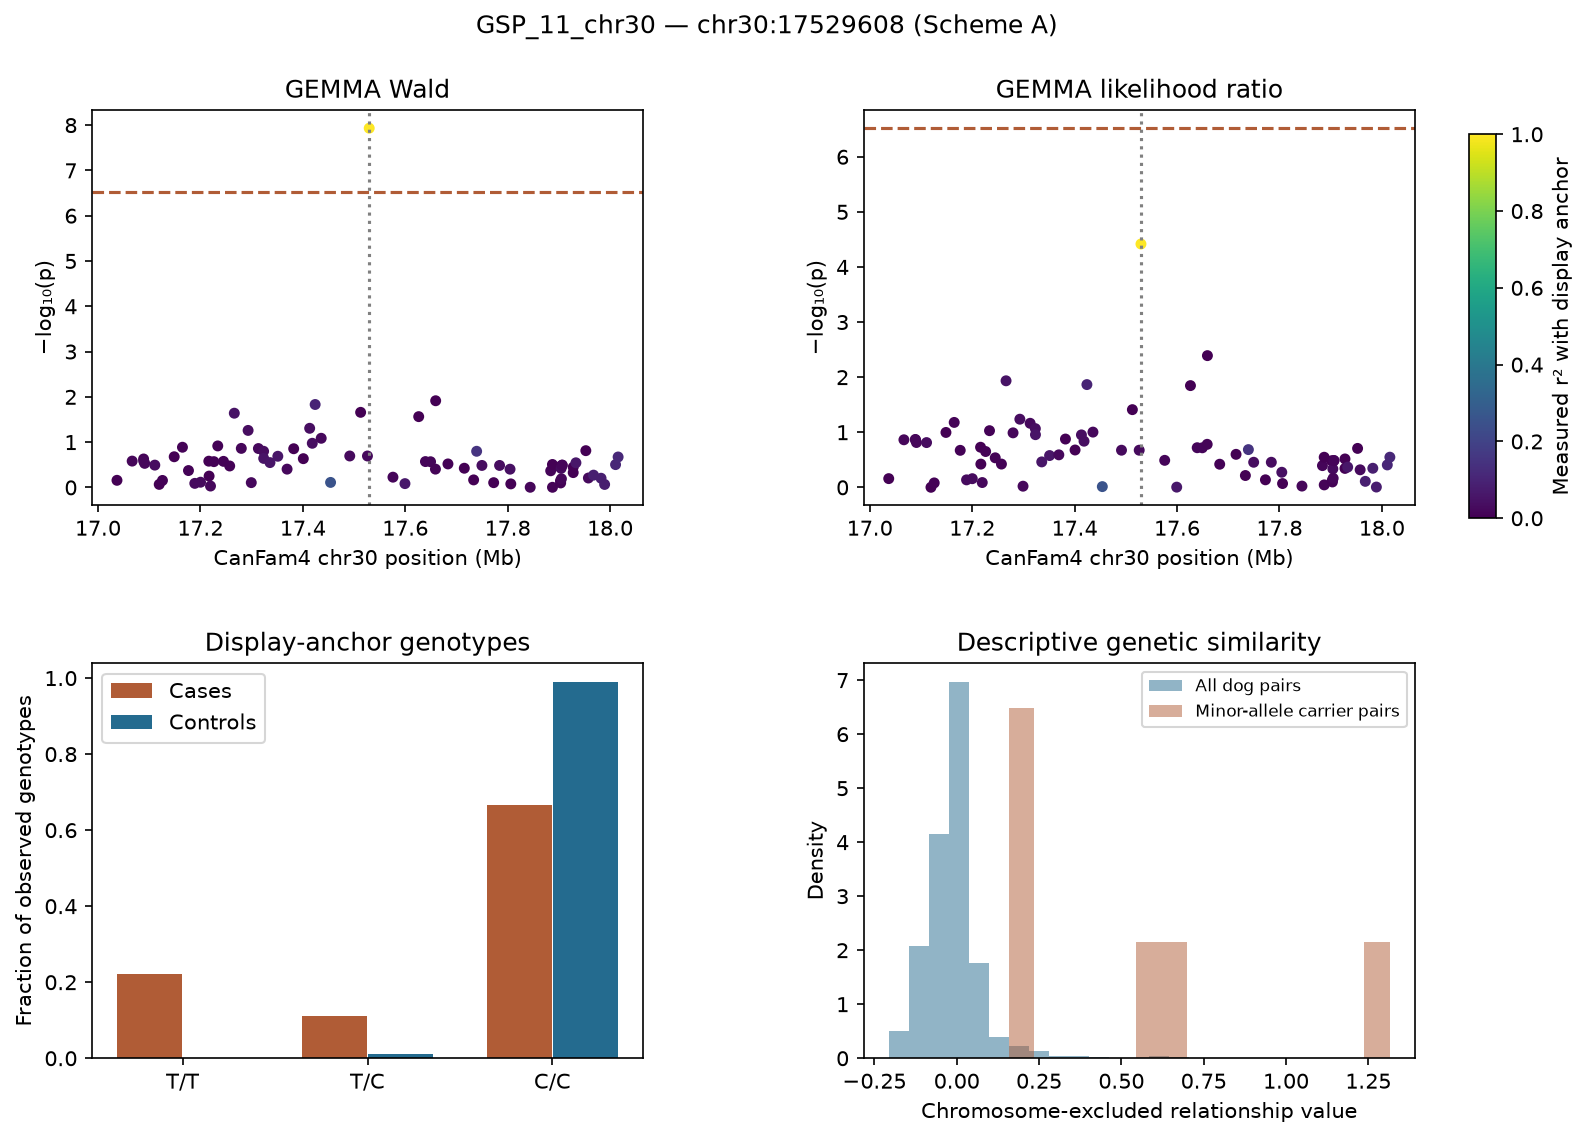

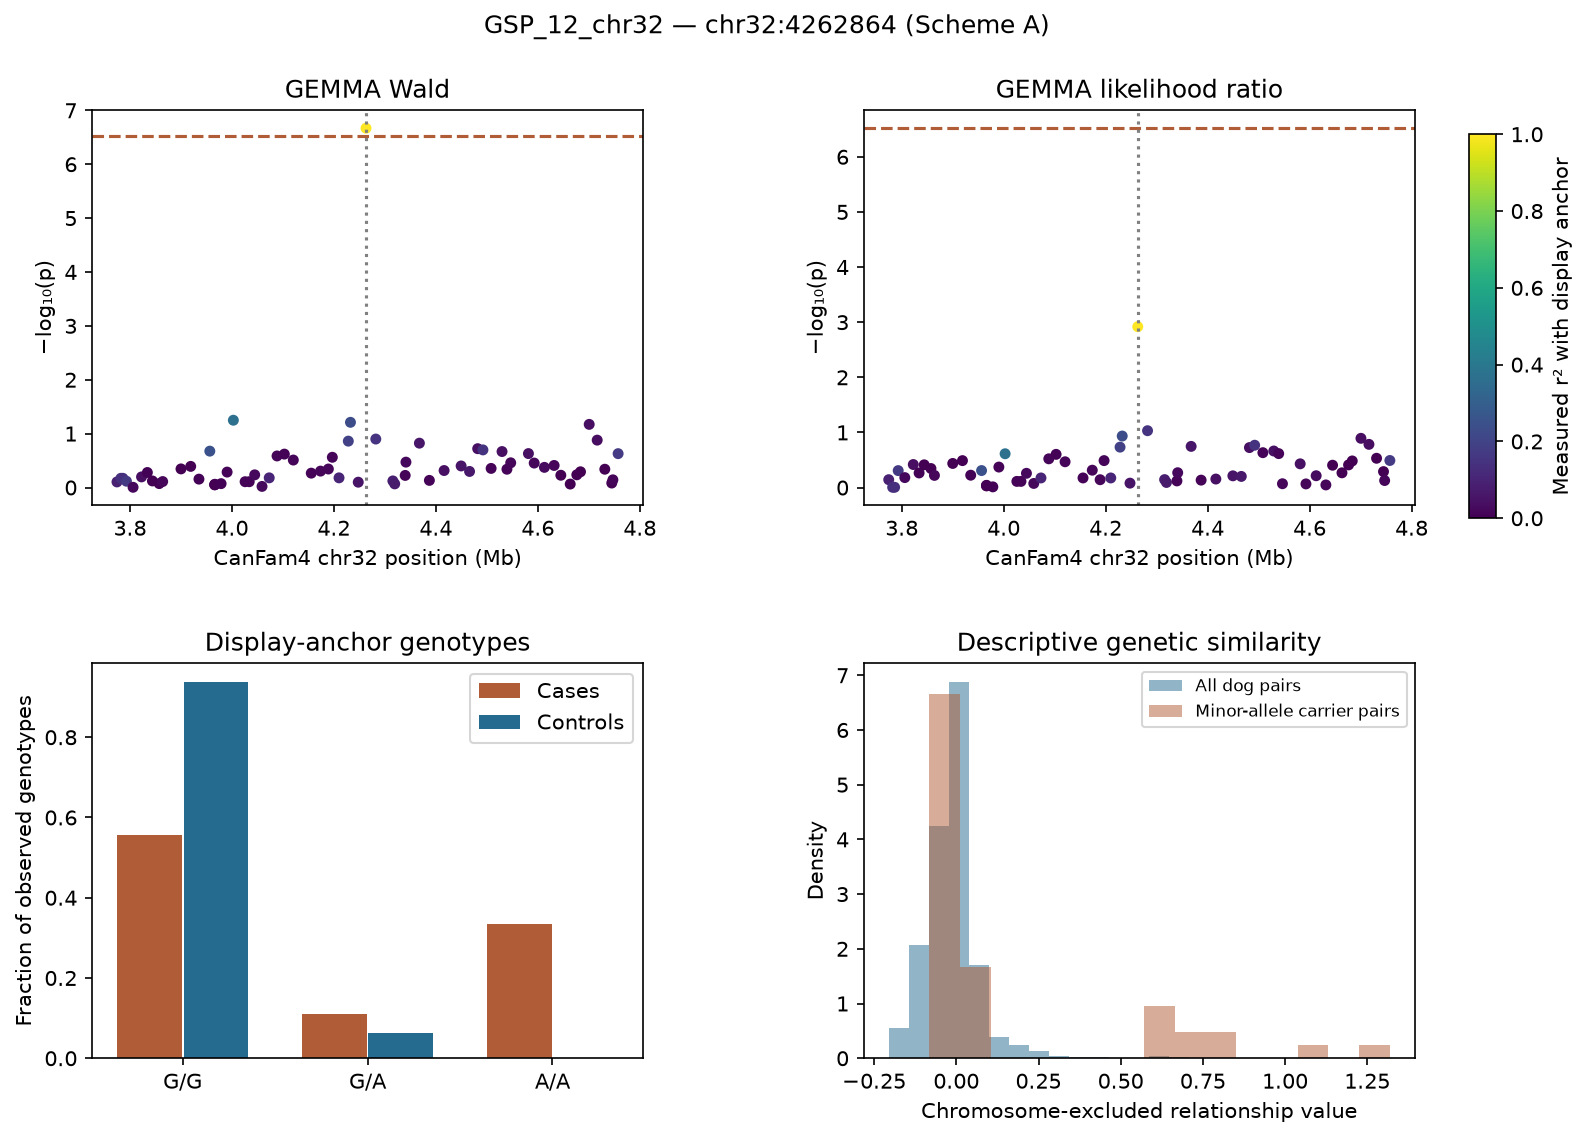

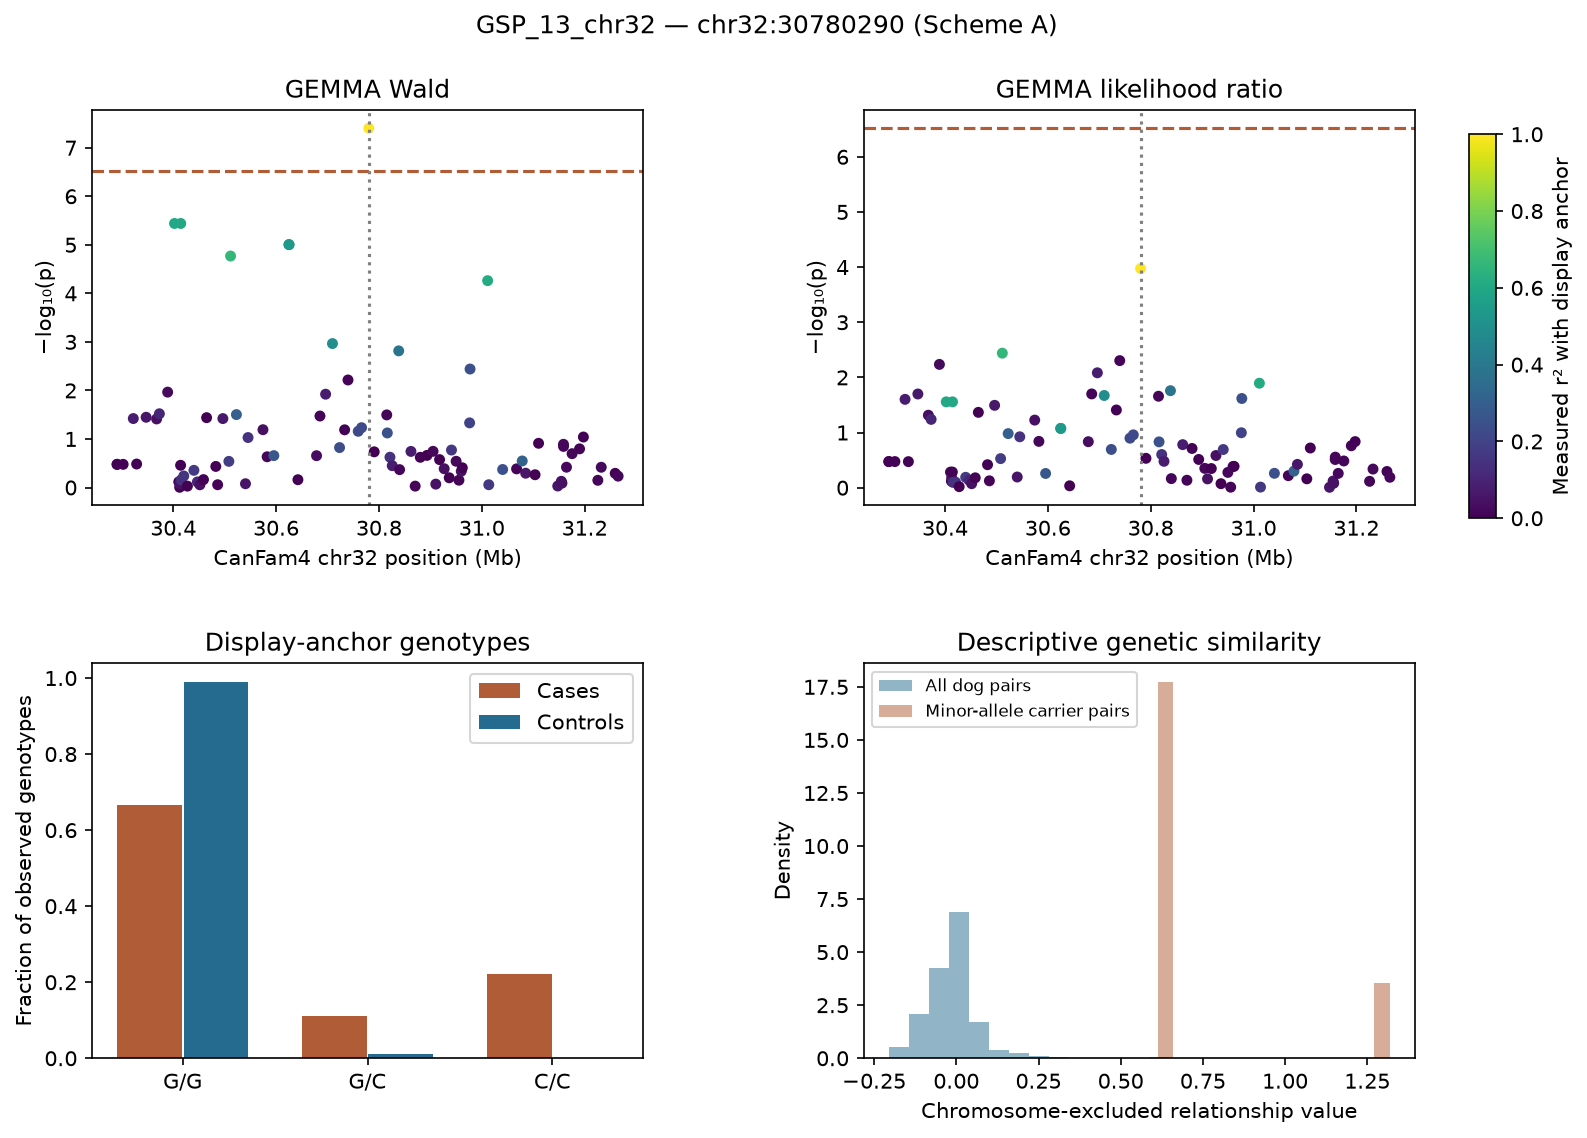

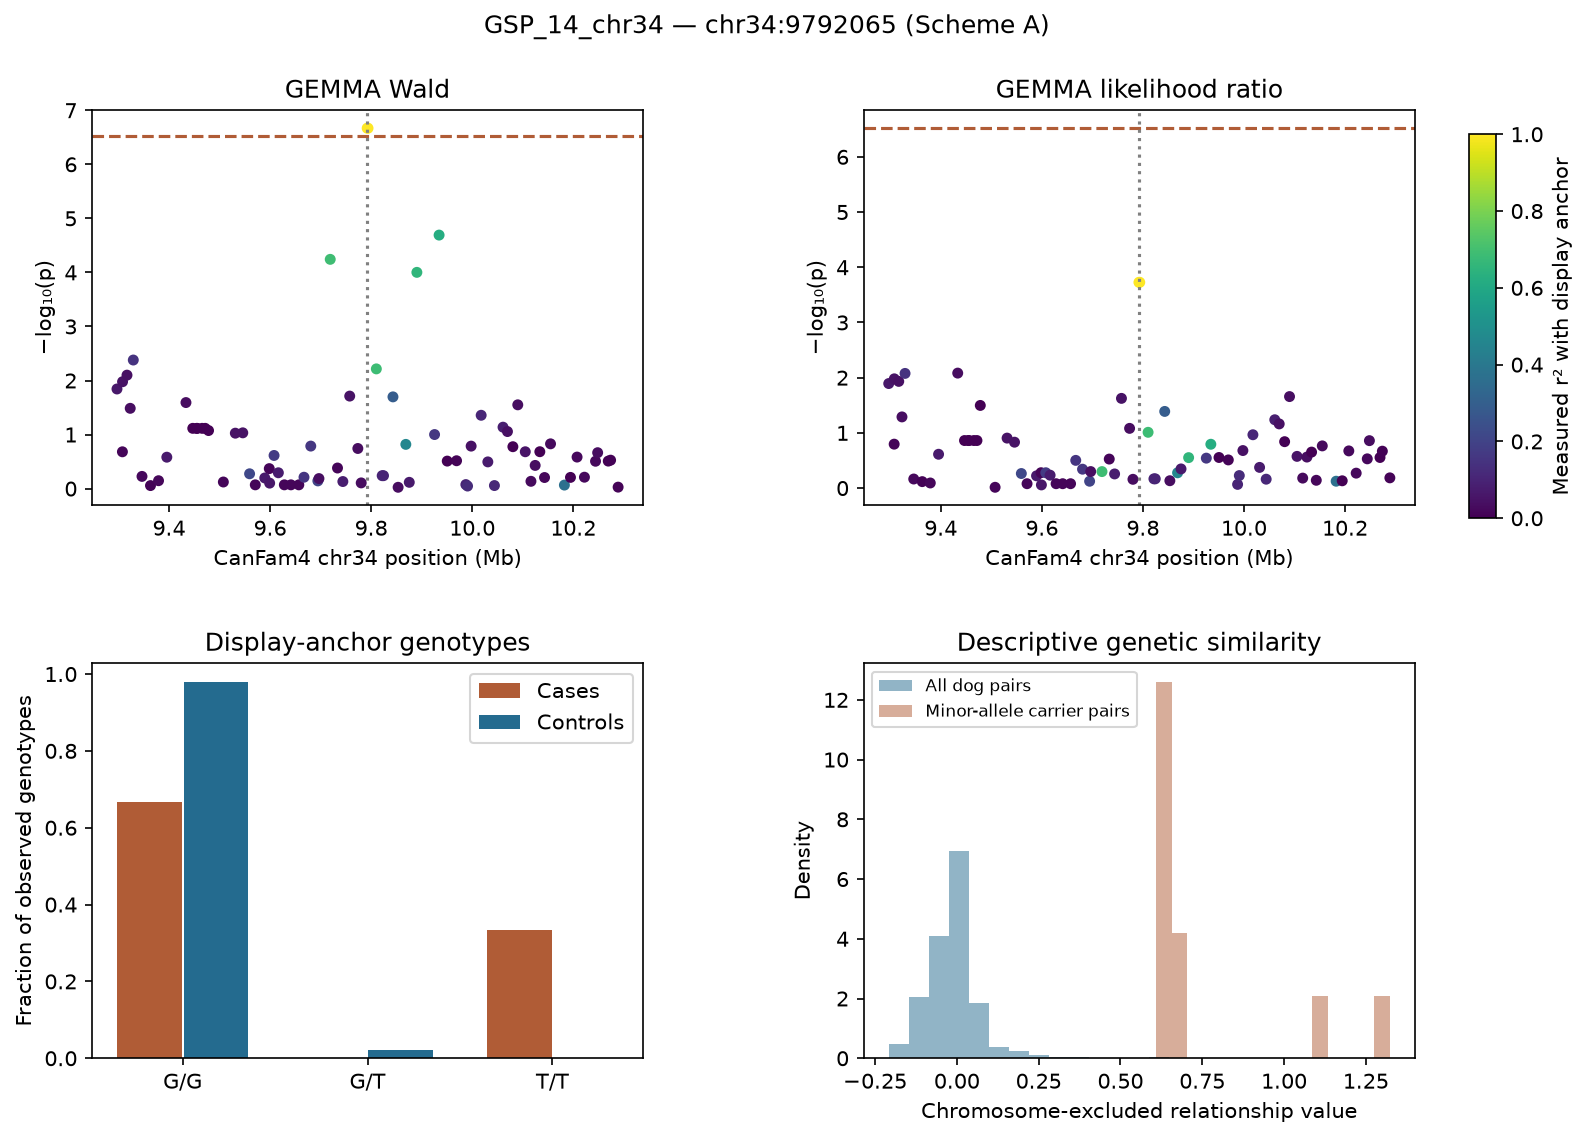

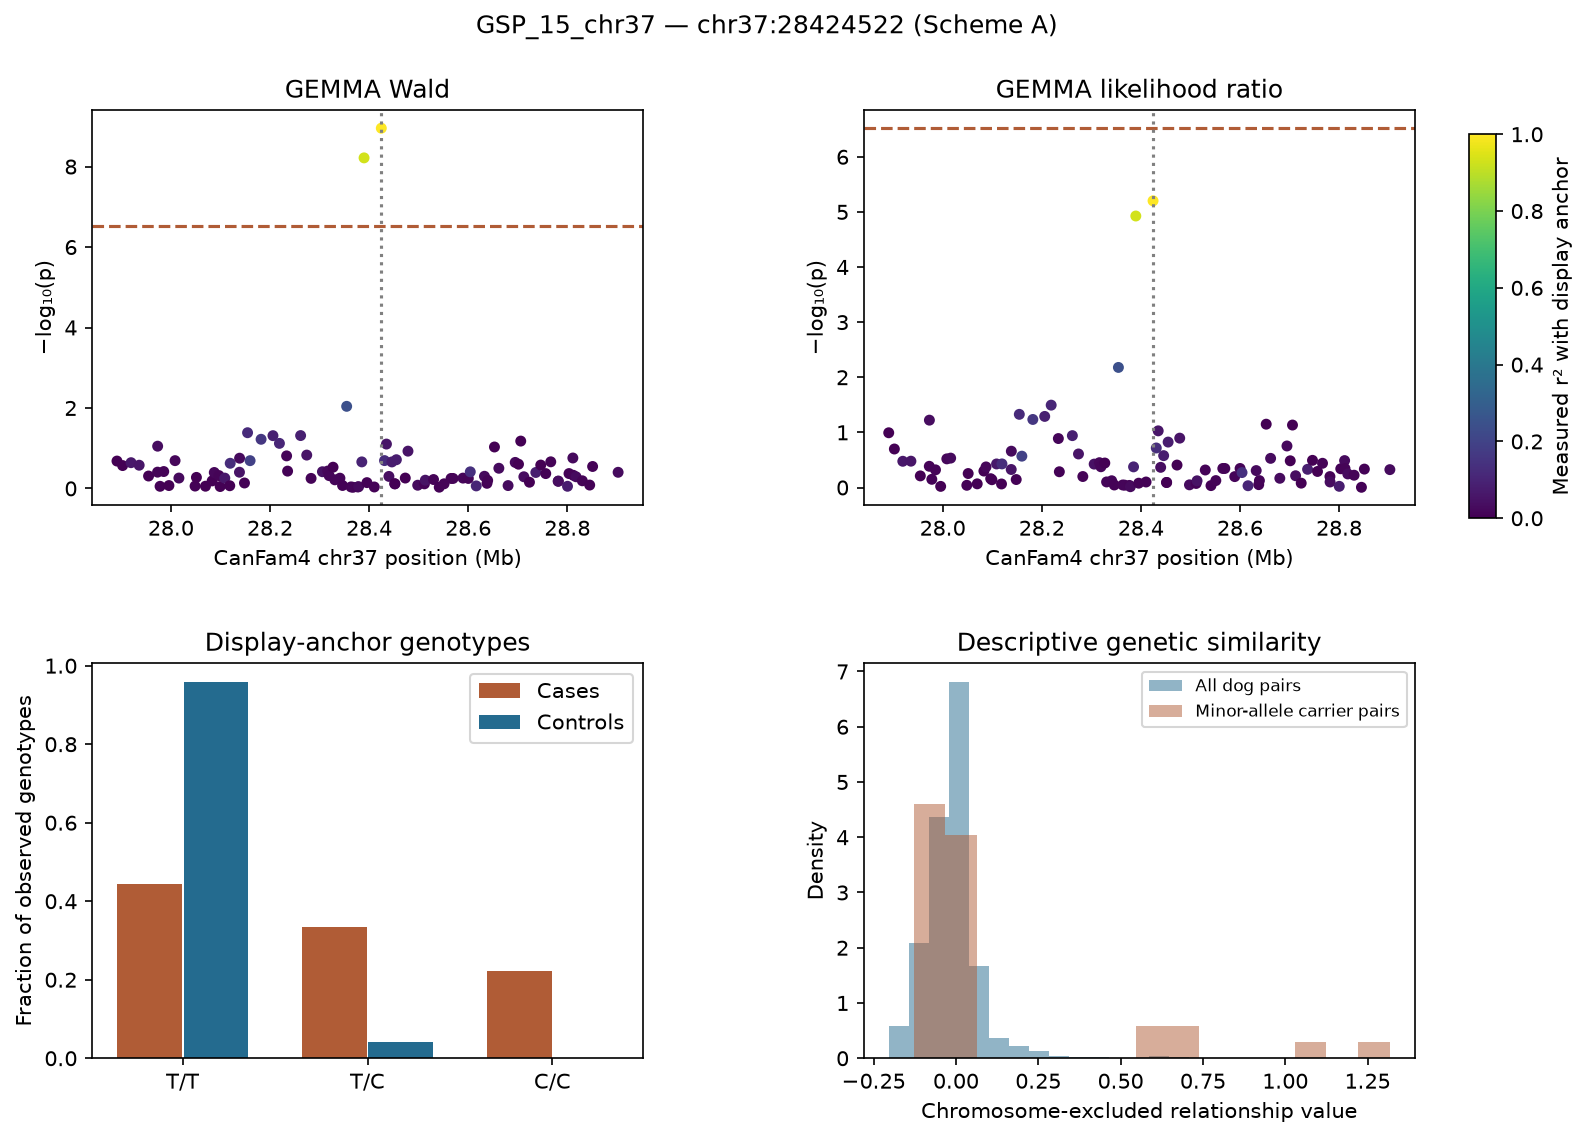

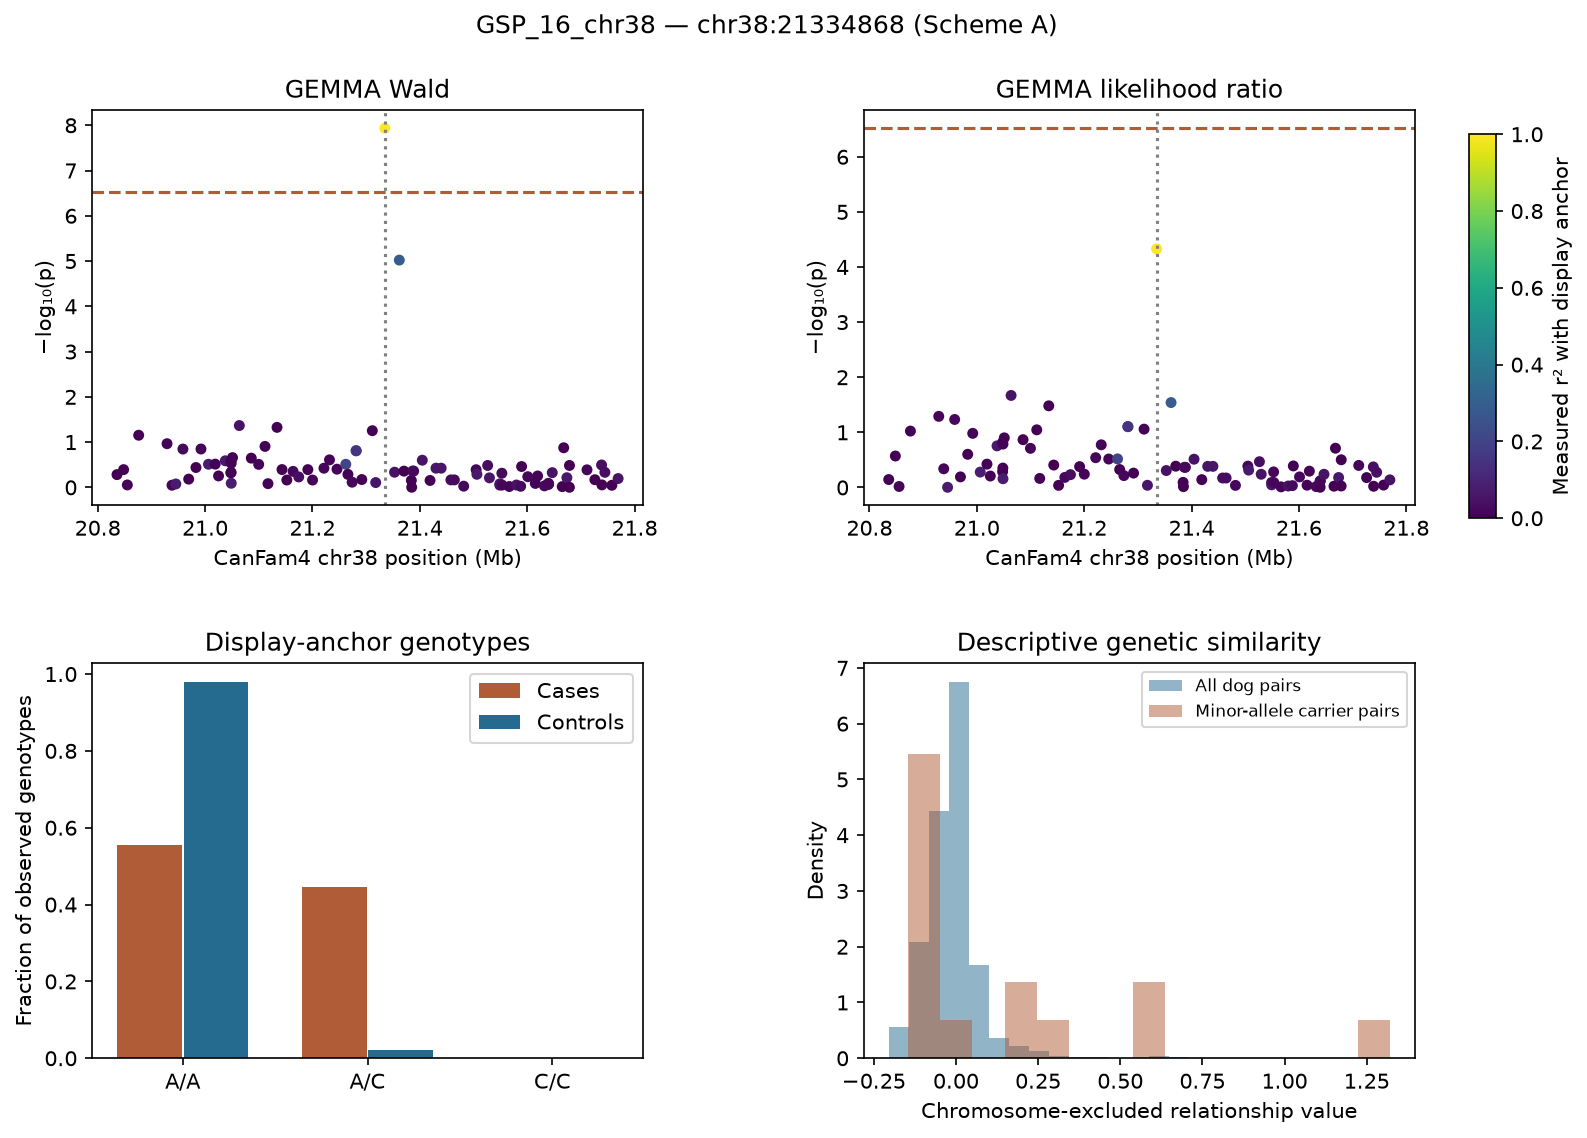

In [4]:
# Display each breed's regional plots for joint review of neighboring evidence and observed genotypes.

for breed in ["LR", "GSP"]:
    display(Markdown(f"## {breed}: candidate-region figures"))
    for region in review["regions"]:
        if region["breed"] != breed: continue
        display(Image(filename=str(review_folder / (region["region"] + ".png"))))

### (Sensitivity Analysis) Compare Fits and Control Groups
- Tables retain GEMMA effects, all probabilities and boundary flags.
- Different tests are not independent support.
- Models are not refitted to improve significance.

In [5]:
# Display each anchor's effects, method-specific probabilities and variance-boundary flags in both schemes.
# This keeps model-fit disagreements visible during candidate review.

with (review_folder / "candidate_models.private.tsv").open(encoding="utf-8", newline="") as handle:
    models = list(csv.DictReader(handle, delimiter="\t"))
lines = ['| Region | Scheme | GEMMA Β | SE | Wald P | Likelihood-Ratio P | GEMMA Score P | GMMAT Score P | REML / ML Boundary |',
         "| :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: |"]
for region in review["regions"]:
    for row in models:
        if row["region"] != region["region"] or row["marker"] != region["anchor"]: continue
        values = [f"{float(row[key]):.3g}" for key in ["GEMMA_beta", "GEMMA_SE", "GEMMA_wald_p", "GEMMA_lrt_p", "GEMMA_score_p", "GMMAT_score_p"]]
        boundary = row["GEMMA_remle_boundary"] + " / " + row["GEMMA_mle_boundary"]
        lines.append("| " + " | ".join([region["region"], row["scheme"], *values, boundary]) + " |")
display(Markdown("\n".join(lines)))

| Region | Scheme | GEMMA Β | SE | Wald P | Likelihood-Ratio P | GEMMA Score P | GMMAT Score P | REML / ML Boundary |
| :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: |
| LR_01_chr5 | A | -0.796 | 0.114 | 1.24e-08 | 1.19e-08 | 1.78e-05 | 4.37e-05 | False / True |
| LR_01_chr5 | B | -0.664 | 0.113 | 5.21e-07 | 4.5e-07 | 5.68e-05 | 0.000103 | False / True |
| LR_02_chr7 | A | 0.573 | 0.0887 | 7.78e-08 | 5.69e-07 | 7.19e-05 | 2.55e-05 | True / True |
| LR_02_chr7 | B | 0.539 | 0.0906 | 3.76e-07 | 1.23e-06 | 8.7e-05 | 3.83e-05 | False / True |
| LR_03_chr8 | A | -0.526 | 0.0727 | 5.77e-09 | 1.25e-08 | 1.8e-05 | 8.96e-06 | True / True |
| LR_03_chr8 | B | -0.5 | 0.0722 | 1.34e-08 | 3.45e-08 | 2.12e-05 | 1.14e-05 | True / True |
| GSP_01_chr1 | A | 0.456 | 0.0776 | 5.28e-08 | 0.000243 | 0.00231 | 0.00518 | True / True |
| GSP_01_chr1 | B | 0.46 | 0.074 | 8.38e-09 | 6.93e-06 | 0.00175 | 0.00426 | True / True |
| GSP_02_chr2 | A | 0.36 | 0.061 | 4.6e-08 | 0.000186 | 0.000467 | 0.000144 | True / True |
| GSP_02_chr2 | B | 0.283 | 0.058 | 3.43e-06 | 0.000207 | 0.00474 | 0.000259 | False / False |
| GSP_03_chr6 | A | 0.33 | 0.0577 | 1.08e-07 | 0.00037 | 0.00249 | 0.00313 | True / True |
| GSP_03_chr6 | B | 0.277 | 0.0606 | 1.26e-05 | 0.000468 | 0.00369 | 0.00341 | False / False |
| GSP_04_chr8 | A | 0.365 | 0.0656 | 2.11e-07 | 0.000716 | 0.0688 | 0.00236 | True / True |
| GSP_04_chr8 | B | 0.369 | 0.0623 | 3.61e-08 | 2.27e-05 | 0.0564 | 0.00171 | True / True |
| GSP_05_chr10 | A | 0.347 | 0.0612 | 1.37e-07 | 0.000886 | 0.00282 | 0.00214 | True / True |
| GSP_05_chr10 | B | 0.351 | 0.0579 | 1.77e-08 | 2.13e-05 | 0.00178 | 0.00141 | True / True |
| GSP_06_chr17 | A | 0.402 | 0.0506 | 2.65e-12 | 6.46e-09 | 4.61e-06 | 3.96e-05 | True / True |
| GSP_06_chr17 | B | 0.405 | 0.0479 | 1.14e-13 | 4.45e-11 | 1.43e-06 | 2.27e-05 | True / True |
| GSP_07_chr17 | A | 0.326 | 0.0581 | 1.73e-07 | 4.88e-07 | 6.88e-06 | 8.76e-05 | False / True |
| GSP_07_chr17 | B | 0.327 | 0.0539 | 1.81e-08 | 1.15e-07 | 3.35e-06 | 4.49e-05 | False / False |
| GSP_08_chr19 | A | 0.387 | 0.0567 | 6.1e-10 | 2.86e-06 | 0.000323 | 0.000215 | True / True |
| GSP_08_chr19 | B | 0.371 | 0.0546 | 5.52e-10 | 3.43e-07 | 8.34e-05 | 0.000201 | False / False |
| GSP_09_chr21 | A | 0.407 | 0.0735 | 2.45e-07 | 7.35e-05 | 0.000696 | 0.00117 | False / False |
| GSP_09_chr21 | B | 0.37 | 0.0657 | 1.3e-07 | 1.36e-05 | 0.0021 | 0.00113 | False / False |
| GSP_10_chr27 | A | 0.453 | 0.0753 | 2.9e-08 | 2.07e-06 | 1.79e-05 | 0.00089 | False / True |
| GSP_10_chr27 | B | 0.457 | 0.0717 | 4.24e-09 | 1.12e-07 | 2.11e-06 | 0.000637 | False / True |
| GSP_11_chr30 | A | -0.485 | 0.0781 | 1.17e-08 | 3.83e-05 | 0.000742 | 0.000664 | False / False |
| GSP_11_chr30 | B | -0.355 | 0.079 | 1.74e-05 | 0.000388 | 0.00207 | 0.00112 | False / False |
| GSP_12_chr32 | A | 0.328 | 0.0589 | 2.15e-07 | 0.00121 | 0.00254 | 0.00316 | True / True |
| GSP_12_chr32 | B | 0.315 | 0.0551 | 9.09e-08 | 0.000103 | 0.00213 | 0.00255 | True / True |
| GSP_13_chr32 | A | 0.473 | 0.0795 | 3.96e-08 | 0.000106 | 0.00101 | 0.00134 | False / False |
| GSP_13_chr32 | B | 0.475 | 0.0757 | 6.5e-09 | 3.38e-06 | 0.000638 | 0.00107 | False / False |
| GSP_14_chr34 | A | 0.413 | 0.0742 | 2.15e-07 | 0.000188 | 0.0012 | 0.00274 | False / False |
| GSP_14_chr34 | B | 0.413 | 0.0694 | 3.05e-08 | 5.74e-06 | 0.000811 | 0.00216 | False / False |
| GSP_15_chr37 | A | 0.424 | 0.0632 | 1.11e-09 | 6.29e-06 | 4.24e-05 | 0.000723 | True / True |
| GSP_15_chr37 | B | 0.399 | 0.0597 | 9.06e-10 | 1.32e-06 | 9.36e-05 | 0.000824 | True / True |
| GSP_16_chr38 | A | 0.62 | 0.0998 | 1.16e-08 | 4.68e-05 | 0.000171 | 0.000377 | True / True |
| GSP_16_chr38 | B | 0.624 | 0.095 | 1.59e-09 | 1.36e-06 | 8.09e-05 | 0.000255 | True / True |

### (Sensitivity Analysis) Allele Frequencies After Omitting One Case
- Omitting one case from frequency counts shows its influence on the descriptive difference.
- This is not a refitted GWAS.

In [6]:
# Display saved changes in allele frequency after omitting one case, alongside carrier-pair similarity.
# These are descriptive sensitivity summaries, not refitted association tests.

lines = ['| Region | Full Case-Minus-Control ALT Frequency | Range After Omitting One Case | Carrier-Pair Mean Similarity | All-Pair Mean Similarity |',
         "| :---: | :---: | :---: | :---: | :---: |"]
def value_or_blank(value):
    return "Unavailable" if value is None else f"{value:.3f}"
for region in review["regions"]:
    lines.append(f"| {region['region']} | {region['case_control_ALT_frequency_difference']:.3f} | "
                 f"{region['leave_one_case_out_frequency_difference_min']:.3f} to {region['leave_one_case_out_frequency_difference_max']:.3f} | "
                 f"{value_or_blank(region['carrier_pair_relationship']['mean'])} | {value_or_blank(region['all_pair_relationship']['mean'])} |")
display(Markdown("\n".join(lines)))

| Region | Full Case-Minus-Control ALT Frequency | Range After Omitting One Case | Carrier-Pair Mean Similarity | All-Pair Mean Similarity |
| :---: | :---: | :---: | :---: | :---: |
| LR_01_chr5 | -0.344 | -0.404 to -0.321 | 0.051 | -0.022 |
| LR_02_chr7 | 0.403 | 0.308 to 0.474 | 0.013 | -0.022 |
| LR_03_chr8 | -0.507 | -0.519 to -0.436 | -0.020 | -0.022 |
| GSP_01_chr1 | 0.273 | 0.182 to 0.307 | 0.838 | -0.009 |
| GSP_02_chr2 | 0.342 | 0.266 to 0.391 | 0.015 | -0.009 |
| GSP_03_chr6 | 0.368 | 0.292 to 0.417 | 0.204 | -0.009 |
| GSP_04_chr8 | 0.307 | 0.224 to 0.349 | 0.064 | -0.009 |
| GSP_05_chr10 | 0.352 | 0.276 to 0.401 | 0.106 | -0.009 |
| GSP_06_chr17 | 0.469 | 0.406 to 0.531 | 0.010 | -0.009 |
| GSP_07_chr17 | 0.443 | 0.380 to 0.505 | 0.059 | -0.009 |
| GSP_08_chr19 | 0.408 | 0.339 to 0.464 | 0.070 | -0.009 |
| GSP_09_chr21 | 0.318 | 0.234 to 0.359 | 0.426 | -0.009 |
| GSP_10_chr27 | 0.323 | 0.240 to 0.365 | 0.042 | -0.009 |
| GSP_11_chr30 | -0.273 | -0.307 to -0.182 | 0.520 | -0.009 |
| GSP_12_chr32 | 0.358 | 0.281 to 0.406 | 0.154 | -0.009 |
| GSP_13_chr32 | 0.273 | 0.182 to 0.307 | 0.743 | -0.009 |
| GSP_14_chr34 | 0.323 | 0.240 to 0.365 | 0.756 | -0.009 |
| GSP_15_chr37 | 0.368 | 0.292 to 0.417 | 0.097 | -0.009 |
| GSP_16_chr38 | 0.212 | 0.177 to 0.240 | 0.158 | -0.009 |

### What This Review Supports
- Results support manual candidate review, not extreme-tail validation or causal inference.
- Family confounding remains possible.
- [Candidate-review methods](../docs/methods/09%20Candidate%20region%20review.md) give the details.